In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### Import the data
* Import statistics data that describe countries in one point

In [2]:
one_point_country_stats_df = pd.read_parquet('../data/by_country/one_point_countries.parquet')

In [3]:
one_point_country_stats_df.head()

,Country,labor_force_mean,labor_force_median,labor_force_std,labor_force_cv,labor_force_min,labor_force_max,labor_force_last,labor_force_growth,labor_force_skew,...,govermment_effective__std,govermment_effective__cv,govermment_effective__min,govermment_effective__max,govermment_effective__last,govermment_effective__growth,govermment_effective__skew,govermment_effective__kurtosis,govermment_effective__trend,iso_a3
0,Australia,13.582,13.585,0.618398,0.045531,12.73,14.50,14.50,0.139042,0.097090,...,0.036180,2.347833e-02,1.47,1.59,1.59,0.039216,-0.346877,-0.627720,0.005273,AUS
1,Austria,4.679,4.650,0.092569,0.019784,4.57,4.83,4.83,0.056893,0.530756,...,0.078968,5.401392e-02,1.33,1.61,1.33,-0.095238,-0.207178,-0.148237,-0.011879,AUT
2,Belgium,5.205,5.180,0.151013,0.029013,5.00,5.42,5.42,0.084000,0.146086,...,0.129016,1.088738e-01,1.04,1.40,1.04,-0.257143,0.542175,-1.048411,-0.037758,BEL
3,Brazil,103.729,103.950,2.291325,0.022090,99.69,106.30,106.10,0.048419,-0.373023,...,0.135632,-3.214025e-01,-0.59,-0.23,-0.55,1.200000,0.321185,-1.620024,-0.038182,BRA
4,Bulgaria,3.255,3.270,0.095525,0.029347,3.09,3.38,3.09,-0.055046,-0.624667,...,0.146969,-5.295130e+16,-0.27,0.17,0.05,-0.444444,-0.794950,-1.012397,-0.022303,BGR


### Search outliers
* Look for outliers
* Plot the boxplot for every feature

In [6]:
def detect_top_outliers(df, top_n=5):
    # Select only numerical columns
    numeric_columns = df.select_dtypes(include=['float64', 'int64']).columns

    outlier_counts = {}

    # Count outliers per column using IQR method
    for col in numeric_columns:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        outliers = df[(df[col] < Q1 - 1.5 * IQR) | (df[col] > Q3 + 1.5 * IQR)]
        outlier_counts[col] = outliers.shape[0]

    # Sort columns by number of outliers (descending)
    sorted_outliers = dict(sorted(outlier_counts.items(), key=lambda item: item[1], reverse=True))

    print("Number of outliers per column (sorted):\n")
    for col, count in sorted_outliers.items():
        print(f"{col}: {count}")

    # Plot boxplots for top N columns with most outliers
    top_columns = list(sorted_outliers.keys())[:top_n]

    plt.figure(figsize=(15, top_n * 2))
    for i, col in enumerate(top_columns, 1):
        plt.subplot(top_n, 1, i)
        sns.boxplot(x=df[col], color='salmon')
        plt.title(f'Boxplot of {col}', fontsize=11)
        plt.tight_layout()

    plt.show()

Number of outliers per column (sorted):

cpi_min: 17
govermment_effective__cv: 16
rule_of_law__cv: 13
investment_median: 12
investment_min: 12
cpi_median: 12
gdp_median: 12
gdp_min: 12
investment_mean: 11
investment_std: 11
investment_max: 11
investment_last: 11
gdp_max: 11
gdp_last: 11
gov_exp_std: 10
gov_exp_trend: 10
investment_trend: 10
gdp_mean: 10
gdp_std: 10
gdp_trend: 10
urban_pop_kurtosis: 9
gov_exp_mean: 9
gov_exp_median: 9
gov_exp_min: 9
gov_exp_max: 9
gov_exp_last: 9
cpi_mean: 9
priv_cred_mean: 9
priv_cred_median: 9
priv_cred_std: 9
priv_cred_min: 9
priv_cred_max: 9
priv_cred_last: 9
priv_cred_trend: 9
govermment_effective__growth: 9
labor_force_trend: 8
agr_land_growth: 8
inflation__growth: 8
labor_force_std: 7
livestock_prod_min: 7
agr_land_trend: 7
rule_of_law__growth: 7
labor_force_mean: 6
labor_force_median: 6
labor_force_max: 6
reserves_std: 6
reserves_trend: 6
cpi_max: 6
cpi_skew: 6
unemployment_kurtosis: 6
tax_revenue__std: 6
labor_force_min: 5
urban_pop_skew: 5
res

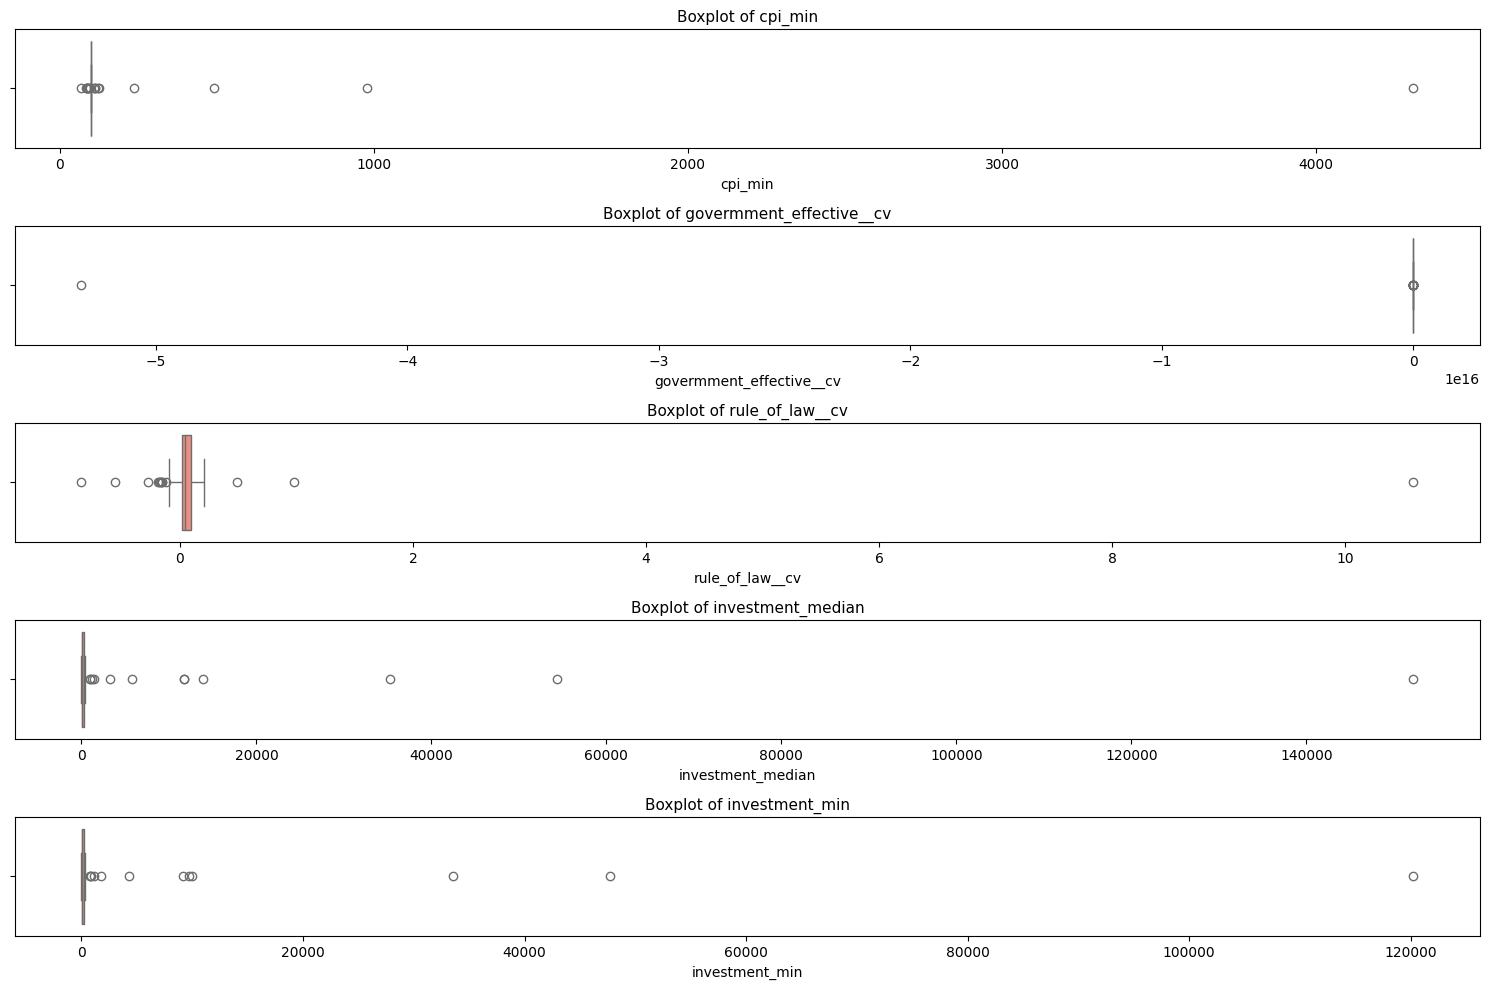

In [7]:
detect_top_outliers(one_point_country_stats_df)

### Apply transformations
* Apply log transformation to selected features
* Apply standard scaler to others
* Plot again the box plot for every feature to see outliers

In [8]:
def adaptive_log_transform(df):
    """
    Applies logarithmic transformation to numeric columns with outliers,
    choosing between log(x) and log1p(x) based on the presence of near-zero values.

    Parameters:
    ----------
    df : pandas.DataFrame
        The input DataFrame containing numeric and non-numeric columns.

    Returns:
    -------
    transformed_df : pandas.DataFrame
        A copy of the original DataFrame with selected numeric columns log-transformed.
        Columns are transformed only if:
            - They contain outliers (based on IQR method).
            - All values are strictly positive.
            - If values are close to zero, log1p(x) is used instead of log(x).
    """

    numeric_cols = df.select_dtypes(include=['float64', 'int64']).columns
    transformed_df = df.copy()

    for col in numeric_cols:
        series = df[col]

        # Check for outliers using IQR
        Q1 = series.quantile(0.25)
        Q3 = series.quantile(0.75)
        IQR = Q3 - Q1
        outliers = series[(series < Q1 - 1.5 * IQR) | (series > Q3 + 1.5 * IQR)]

        # Proceed only if outliers exist and all values are positive
        if outliers.shape[0] > 0 and (series > 0).all():
            min_val = series.min()

            # Use log1p if values are close to zero
            if min_val < 1:
                transformed_df[col] = np.log1p(series)
                print(f"Applied log1p transformation to column: {col}")
            else:
                transformed_df[col] = np.log(series)
                print(f"Applied log transformation to column: {col}")

    return transformed_df

In [9]:
df_log_transf = adaptive_log_transform(one_point_country_stats_df)

Applied log1p transformation to column: labor_force_mean
Applied log1p transformation to column: labor_force_median
Applied log1p transformation to column: labor_force_std
Applied log1p transformation to column: labor_force_min
Applied log1p transformation to column: labor_force_max
Applied log1p transformation to column: labor_force_last
Applied log transformation to column: livestock_prod_mean
Applied log transformation to column: livestock_prod_median
Applied log1p transformation to column: livestock_prod_std
Applied log1p transformation to column: livestock_prod_cv
Applied log transformation to column: livestock_prod_min
Applied log transformation to column: livestock_prod_max
Applied log transformation to column: livestock_prod_last
Applied log transformation to column: urban_pop_mean
Applied log transformation to column: urban_pop_median
Applied log transformation to column: urban_pop_min
Applied log transformation to column: urban_pop_max
Applied log transformation to column: ur

Number of outliers per column (sorted):

cpi_min: 17
govermment_effective__cv: 16
rule_of_law__cv: 13
cpi_median: 11
urban_pop_kurtosis: 9
cpi_mean: 9
priv_cred_trend: 9
govermment_effective__growth: 9
labor_force_trend: 8
agr_land_growth: 8
inflation__growth: 8
livestock_prod_min: 7
agr_land_trend: 7
rule_of_law__growth: 7
reserves_trend: 6
cpi_skew: 6
unemployment_kurtosis: 6
edu_spending__max: 6
urban_pop_skew: 5
reserves_growth: 5
cpi_max: 5
cpi_last: 5
gdp_skew: 5
priv_cred_kurtosis: 5
labor_force_kurtosis: 4
livestock_prod_median: 4
gov_exp_skew: 4
reserves_kurtosis: 4
cpi_std: 4
cpi_trend: 4
priv_cred_growth: 4
tax_revenue__std: 4
tax_revenue__cv: 4
tax_revenue__skew: 4
inflation__trend: 4
edu_spending__cv: 4
edu_spending__kurtosis: 4
labor_force_std: 3
livestock_prod_mean: 3
livestock_prod_cv: 3
livestock_prod_max: 3
livestock_prod_skew: 3
livestock_prod_trend: 3
agr_land_std: 3
agr_land_cv: 3
agr_land_skew: 3
gov_exp_kurtosis: 3
reserves_cv: 3
investment_mean: 3
investment_med

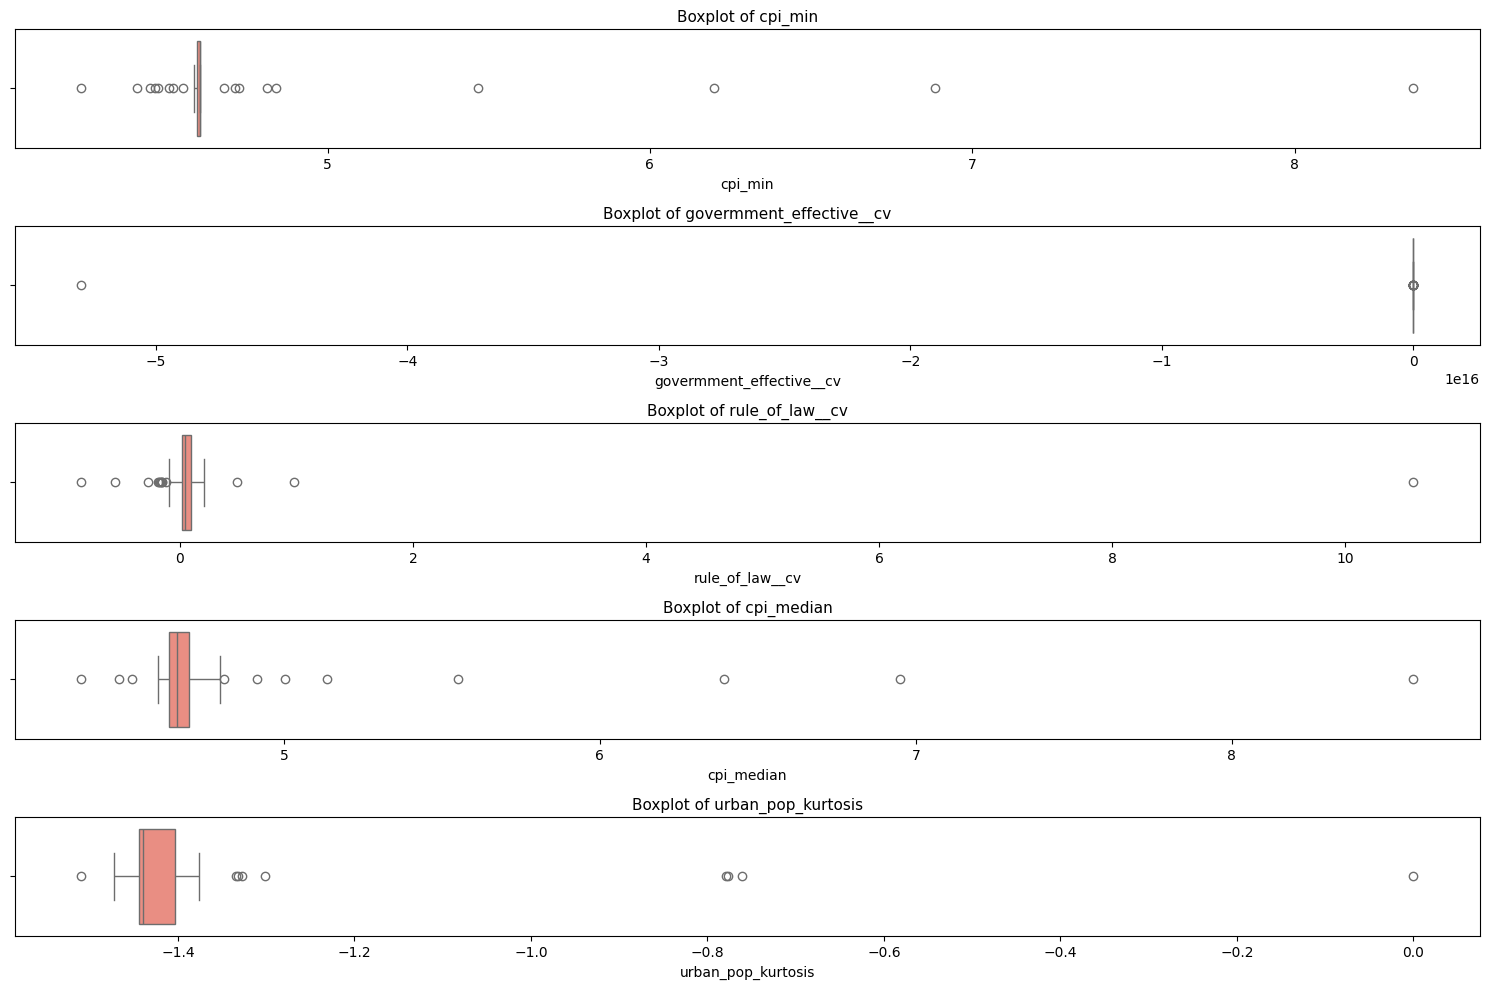

In [10]:
detect_top_outliers(df_log_transf)

In [11]:
from sklearn.preprocessing import StandardScaler

In [15]:
def apply_standard_scaler(original_df, log_transformed_df):
    """
    Applies StandardScaler to numeric columns that were not log-transformed.

    Parameters:
    ----------
    original_df : pandas.DataFrame
        The original DataFrame before any transformations.

    log_transformed_df : pandas.DataFrame
        The DataFrame after applying log transformations to selected columns.

    Returns:
    -------
    scaled_df : pandas.DataFrame
        A copy of the log_transformed_df with StandardScaler applied to numeric columns
        that were not previously log-transformed.
    """

    # Identify numeric columns in both DataFrames
    original_numeric = original_df.select_dtypes(include=['float64', 'int64']).columns
    transformed_numeric = log_transformed_df.select_dtypes(include=['float64', 'int64']).columns

    # Columns that were not transformed (same values as original)
    untouched_columns = [
        col for col in original_numeric
        if col in transformed_numeric and original_df[col].equals(log_transformed_df[col])
    ]

    # Apply StandardScaler to untouched numeric columns
    scaler = StandardScaler()
    scaled_df = log_transformed_df.copy()
    scaled_df[untouched_columns] = scaler.fit_transform(original_df[untouched_columns])

    print(f"Applied StandardScaler to columns: {untouched_columns}")
    return scaled_df, untouched_columns

In [16]:
df_scaled, untouched_colums = apply_standard_scaler(one_point_country_stats_df, df_log_transf)

Applied StandardScaler to columns: ['labor_force_cv', 'labor_force_growth', 'labor_force_skew', 'labor_force_kurtosis', 'labor_force_trend', 'livestock_prod_growth', 'livestock_prod_skew', 'livestock_prod_kurtosis', 'livestock_prod_trend', 'agr_land_mean', 'agr_land_median', 'agr_land_std', 'agr_land_cv', 'agr_land_min', 'agr_land_max', 'agr_land_last', 'agr_land_growth', 'agr_land_skew', 'agr_land_kurtosis', 'agr_land_trend', 'urban_pop_std', 'urban_pop_cv', 'urban_pop_growth', 'urban_pop_skew', 'urban_pop_kurtosis', 'urban_pop_trend', 'gov_exp_skew', 'gov_exp_kurtosis', 'reserves_growth', 'reserves_skew', 'reserves_kurtosis', 'reserves_trend', 'investment_skew', 'investment_kurtosis', 'cpi_growth', 'cpi_skew', 'cpi_kurtosis', 'cpi_trend', 'gdp_skew', 'gdp_kurtosis', 'priv_cred_growth', 'priv_cred_skew', 'priv_cred_kurtosis', 'priv_cred_trend', 'unemployment_cv', 'unemployment_growth', 'unemployment_skew', 'unemployment_kurtosis', 'unemployment_trend', 'rule_of_law__mean', 'rule_of_la

In [26]:
df_final = pd.concat([df_log_transf.drop(columns=untouched_colums), df_scaled[untouched_colums]], axis=1)
df_final.head()

,Country,labor_force_mean,labor_force_median,labor_force_std,labor_force_min,labor_force_max,labor_force_last,livestock_prod_mean,livestock_prod_median,livestock_prod_std,...,govermment_effective__mean,govermment_effective__median,govermment_effective__cv,govermment_effective__min,govermment_effective__max,govermment_effective__last,govermment_effective__growth,govermment_effective__skew,govermment_effective__kurtosis,govermment_effective__trend
0,Australia,2.679788,2.679994,0.481437,2.619583,2.740840,2.740840,4.528397,4.508659,1.820075,...,0.907532,0.896973,0.138675,0.997664,0.783123,0.991862,-0.183282,-0.557676,0.740819,0.517477
1,Austria,1.736775,1.731656,0.088532,1.717395,1.763017,1.763017,4.614130,4.615121,0.377242,...,0.800186,0.807935,0.138675,0.812366,0.810674,0.651612,-0.219351,-0.255483,1.592734,-0.060887
2,Belgium,1.825355,1.821318,0.140643,1.791759,1.859418,1.859418,4.636378,4.628887,0.985339,...,0.423795,0.390140,0.138675,0.428533,0.521389,0.272102,-0.262785,1.365494,-0.006636,-0.933542
3,Brazil,4.651376,4.653484,1.191290,4.612046,4.675629,4.673763,4.672829,4.675629,1.646041,...,-1.759814,-1.863213,0.138675,-1.728868,-1.724013,-1.808661,0.128118,0.887456,-1.022241,-0.947848
4,Bulgaria,1.448095,1.451614,0.091234,1.408545,1.477049,1.408545,4.527641,4.503691,1.688591,...,-1.186396,-1.109812,-7.211103,-1.305329,-1.172995,-1.023467,-0.313032,-1.526935,0.057350,-0.412401


Number of outliers per column (sorted):

govermment_effective__cv: 20
cpi_min: 17
rule_of_law__cv: 13
cpi_median: 11
cpi_mean: 9
urban_pop_kurtosis: 9
priv_cred_trend: 9
govermment_effective__growth: 9
labor_force_trend: 8
agr_land_growth: 8
inflation__growth: 8
livestock_prod_min: 7
agr_land_trend: 7
rule_of_law__growth: 7
edu_spending__max: 6
reserves_trend: 6
cpi_skew: 6
unemployment_kurtosis: 6
cpi_max: 5
cpi_last: 5
urban_pop_skew: 5
reserves_growth: 5
gdp_skew: 5
priv_cred_kurtosis: 5
livestock_prod_median: 4
cpi_std: 4
tax_revenue__std: 4
tax_revenue__cv: 4
edu_spending__cv: 4
labor_force_kurtosis: 4
gov_exp_skew: 4
reserves_kurtosis: 4
cpi_trend: 4
priv_cred_growth: 4
tax_revenue__skew: 4
inflation__trend: 4
edu_spending__kurtosis: 4
labor_force_std: 3
livestock_prod_mean: 3
livestock_prod_cv: 3
livestock_prod_max: 3
reserves_cv: 3
investment_mean: 3
investment_median: 3
investment_min: 3
gdp_median: 3
gdp_min: 3
priv_cred_mean: 3
priv_cred_median: 3
priv_cred_min: 3
inflation_

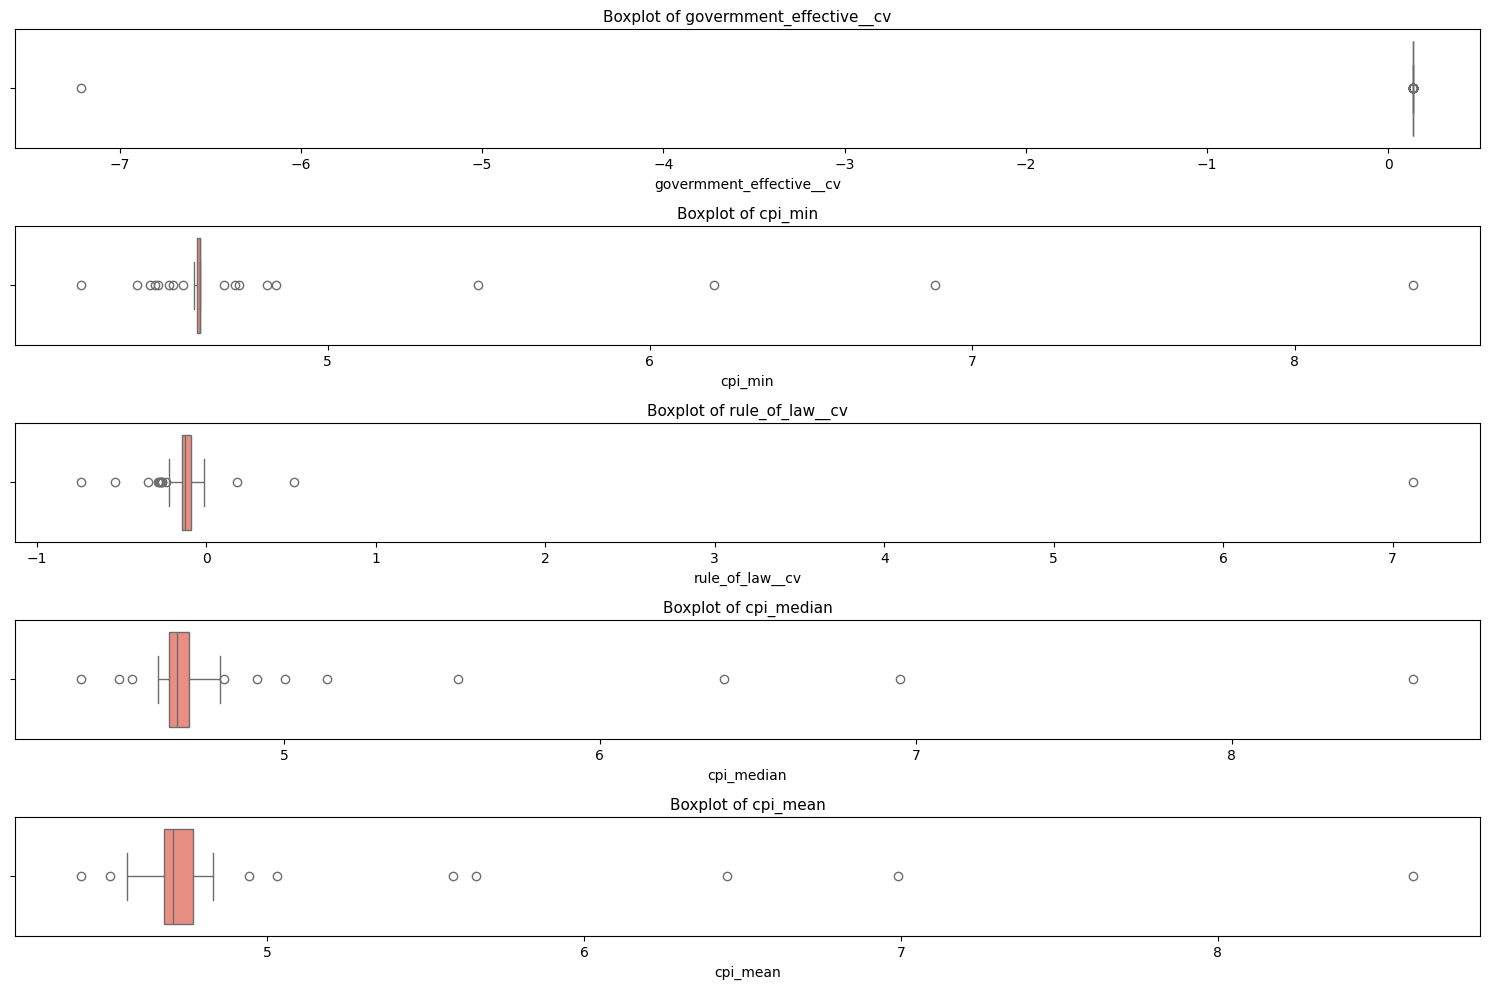

In [20]:
detect_top_outliers(df_final)

### Develop Cluster Kmeans random
* Without elbow method
* Without silhouette plot for quality
* With 3 clusters
* Export df with country, iso_a3, cluster category and continent in parquet format, manage missing values before importing

In [22]:
from sklearn.cluster import KMeans

In [31]:
km = KMeans(n_clusters=3,
            init='k-means++',
            n_init=10,
            max_iter=100,
            random_state=42)

In [27]:
df_cluster_input = df_final.select_dtypes(include='number')

In [29]:
df_cluster_input.head()

,labor_force_mean,labor_force_median,labor_force_std,labor_force_min,labor_force_max,labor_force_last,livestock_prod_mean,livestock_prod_median,livestock_prod_std,livestock_prod_cv,...,govermment_effective__mean,govermment_effective__median,govermment_effective__cv,govermment_effective__min,govermment_effective__max,govermment_effective__last,govermment_effective__growth,govermment_effective__skew,govermment_effective__kurtosis,govermment_effective__trend
0,2.679788,2.679994,0.481437,2.619583,2.740840,2.740840,4.528397,4.508659,1.820075,0.054347,...,0.907532,0.896973,0.138675,0.997664,0.783123,0.991862,-0.183282,-0.557676,0.740819,0.517477
1,1.736775,1.731656,0.088532,1.717395,1.763017,1.763017,4.614130,4.615121,0.377242,0.004531,...,0.800186,0.807935,0.138675,0.812366,0.810674,0.651612,-0.219351,-0.255483,1.592734,-0.060887
2,1.825355,1.821318,0.140643,1.791759,1.859418,1.859418,4.636378,4.628887,0.985339,0.016140,...,0.423795,0.390140,0.138675,0.428533,0.521389,0.272102,-0.262785,1.365494,-0.006636,-0.933542
3,4.651376,4.653484,1.191290,4.612046,4.675629,4.673763,4.672829,4.675629,1.646041,0.038379,...,-1.759814,-1.863213,0.138675,-1.728868,-1.724013,-1.808661,0.128118,0.887456,-1.022241,-0.947848
4,1.448095,1.451614,0.091234,1.408545,1.477049,1.408545,4.527641,4.503691,1.688591,0.046573,...,-1.186396,-1.109812,-7.211103,-1.305329,-1.172995,-1.023467,-0.313032,-1.526935,0.057350,-0.412401


In [32]:
km.fit(df_cluster_input)

,n_clusters,3
,init,'k-means++'
,n_init,10
,max_iter,100
,tol,0.0001
,verbose,0
,random_state,42
,copy_x,True
,algorithm,'lloyd'


In [33]:
len(km.labels_)

53

In [34]:
df_final['cluster'] = km.labels_

In [35]:
df_final.head()

,Country,labor_force_mean,labor_force_median,labor_force_std,labor_force_min,labor_force_max,labor_force_last,livestock_prod_mean,livestock_prod_median,livestock_prod_std,...,govermment_effective__median,govermment_effective__cv,govermment_effective__min,govermment_effective__max,govermment_effective__last,govermment_effective__growth,govermment_effective__skew,govermment_effective__kurtosis,govermment_effective__trend,cluster
0,Australia,2.679788,2.679994,0.481437,2.619583,2.740840,2.740840,4.528397,4.508659,1.820075,...,0.896973,0.138675,0.997664,0.783123,0.991862,-0.183282,-0.557676,0.740819,0.517477,2
1,Austria,1.736775,1.731656,0.088532,1.717395,1.763017,1.763017,4.614130,4.615121,0.377242,...,0.807935,0.138675,0.812366,0.810674,0.651612,-0.219351,-0.255483,1.592734,-0.060887,1
2,Belgium,1.825355,1.821318,0.140643,1.791759,1.859418,1.859418,4.636378,4.628887,0.985339,...,0.390140,0.138675,0.428533,0.521389,0.272102,-0.262785,1.365494,-0.006636,-0.933542,1
3,Brazil,4.651376,4.653484,1.191290,4.612046,4.675629,4.673763,4.672829,4.675629,1.646041,...,-1.863213,0.138675,-1.728868,-1.724013,-1.808661,0.128118,0.887456,-1.022241,-0.947848,2
4,Bulgaria,1.448095,1.451614,0.091234,1.408545,1.477049,1.408545,4.527641,4.503691,1.688591,...,-1.109812,-7.211103,-1.305329,-1.172995,-1.023467,-0.313032,-1.526935,0.057350,-0.412401,1


In [37]:
import geopandas as gpd
import country_converter as coco

In [38]:
df_final[df_final['Country'].isin(['United Kingdom', 'South Africa', 'South Korea'])]

,Country,labor_force_mean,labor_force_median,labor_force_std,labor_force_min,labor_force_max,labor_force_last,livestock_prod_mean,livestock_prod_median,livestock_prod_std,...,govermment_effective__median,govermment_effective__cv,govermment_effective__min,govermment_effective__max,govermment_effective__last,govermment_effective__growth,govermment_effective__skew,govermment_effective__kurtosis,govermment_effective__trend,cluster
44,South Africa,3.263773,3.253277,0.793224,3.210440,3.337192,3.337192,4.621634,4.635214,1.317365,...,-1.123510,0.138675,-1.292093,-1.228096,-1.429151,-1.159562,-1.432890,0.075030,-1.141998,2
45,South Korea,3.394542,3.391315,0.459170,3.369018,3.424263,3.424263,4.658142,4.671426,1.607242,...,0.629858,0.138675,0.402062,0.521389,0.743218,-0.093860,-0.822060,-1.023290,2.058419,0
51,United Kingdom,3.568772,3.568405,0.374171,3.551914,3.588783,3.588783,4.647367,4.655863,1.143128,...,0.636708,0.138675,0.587361,0.755572,0.429140,-0.263859,0.604031,-0.374086,-1.293231,2


In [39]:
df_final['ISO_A3'] = coco.convert(names=df_final['Country'], to='ISO3')

In [42]:
countries_clusters_kmean_plusplus = df_final[['Country', 'ISO_A3', 'cluster']]
countries_clusters_kmean_plusplus

,Country,ISO_A3,cluster
0,Australia,AUS,2
1,Austria,AUT,1
2,Belgium,BEL,1
3,Brazil,BRA,2
4,Bulgaria,BGR,1
5,Canada,CAN,2
6,Chile,CHL,0
7,Colombia,COL,0
8,Croatia,HRV,1
9,Cyprus,CYP,1


In [43]:
countries_clusters_kmean_plusplus.to_parquet('../data/clusters/clusters_kmean_plusplus.parquet')

### Import and clean data for create synthetic data
* Import the data for hpi by country
* Observe if have Pararguay country
* Look if have the same countries that the df with the culsters
* Look if the name of the countries are in the same format "-" or "_"
* Delete countries that do not exist in the HPI dataframe

In [36]:
hpi_df = pd.read_parquet('../data/clean_hpi.parquet')

In [44]:
hpi_df['Paraguay']

KeyError: 'Paraguay'

In [45]:
hpi_df.shape

(15, 58)

In [47]:
countries_clusters_kmean_plusplus.shape

(53, 3)

In [48]:
def clean_column_names(df):
    """
    Replaces hyphens '-' with spaces in column names of a DataFrame.

    Parameters:
    ----------
    df : pandas.DataFrame
        The input DataFrame whose column names may contain hyphens.

    Returns:
    -------
    df_renamed : pandas.DataFrame
        A copy of the original DataFrame with updated column names.
    """
    df_renamed = df.copy()
    df_renamed.columns = [col.replace('-', ' ') for col in df.columns]
    return df_renamed


In [49]:
df_hpi = clean_column_names(hpi_df)
df_hpi.shape

(15, 58)

In [50]:
def find_countries_missing_from_clusters(df_hpi, df_clusters, country_column='Country'):
    """
    Identifies which countries are present in the HPI DataFrame but missing from the cluster DataFrame.

    Parameters:
    - df_hpi: DataFrame where columns are country names and rows are years (House Price Index data)
    - df_clusters: DataFrame with country names and cluster assignments
    - country_column: Name of the column in df_clusters that contains country names (default: 'Country')

    Returns:
    - List of country names that are in df_hpi but not in df_clusters
    """

    # Extract country names from HPI DataFrame (column headers)
    hpi_countries = set(df_hpi.columns)

    # Extract country names from cluster DataFrame
    cluster_countries = set(df_clusters[country_column].unique())

    # Find countries present in HPI but missing from clusters
    missing_countries = hpi_countries - cluster_countries

    # Print results
    if missing_countries:
        print("Countries in HPI that are missing from the cluster DataFrame:")
        for country in sorted(missing_countries):
            print(f" - {country}")
    else:
        print("All countries in the HPI DataFrame are present in the cluster DataFrame.")

    return list(missing_countries)

In [51]:
find_countries_missing_from_clusters(df_hpi, countries_clusters_kmean_plusplus)

Countries in HPI that are missing from the cluster DataFrame:
 - China
 - Czech Republic
 - Hong Kong
 - Indonesia
 - Macedonia
 - Morocco
 - Year


['Hong Kong',
 'China',
 'Czech Republic',
 'Macedonia',
 'Year',
 'Indonesia',
 'Morocco']

In [57]:
print(list(df_hpi.columns))

['Year', 'Australia', 'Austria', 'Belgium', 'Brazil', 'Bulgaria', 'Canada', 'Chile', 'China', 'Colombia', 'Croatia', 'Cyprus', 'Czech Republic', 'Denmark', 'Estonia', 'Finland', 'France', 'Germany', 'Greece', 'Hong Kong', 'Hungary', 'Iceland', 'India', 'Indonesia', 'Ireland', 'Israel', 'Italy', 'Japan', 'Latvia', 'Lithuania', 'Luxembourg', 'Macedonia', 'Malaysia', 'Malta', 'Mexico', 'Morocco', 'Netherlands', 'New Zealand', 'Norway', 'Peru', 'Philippines', 'Poland', 'Portugal', 'Romania', 'Russia', 'Serbia', 'Singapore', 'Slovakia', 'Slovenia', 'South Africa', 'South Korea', 'Spain', 'Sweden', 'Switzerland', 'Thailand', 'Turkey', 'USA', 'United Kingdom']


In [58]:
clusters_countries = pd.read_parquet('../data/clusters/clusters_kmean_plusplus.parquet')

In [60]:
print(list(clusters_countries.Country))

['Australia', 'Austria', 'Belgium', 'Brazil', 'Bulgaria', 'Canada', 'Chile', 'Colombia', 'Croatia', 'Cyprus', 'Czech', 'Denmark', 'Estonia', 'Finland', 'France', 'Germany', 'Greece', 'Hungary', 'Iceland', 'India', 'Ireland', 'Israel', 'Italy', 'Japan', 'Latvia', 'Lithuania', 'Luxembourg', 'Malaysia', 'Malta', 'Mexico', 'Netherlands', 'New Zealand', 'Norway', 'Paraguay', 'Peru', 'Philippines', 'Poland', 'Portugal', 'Romania', 'Russia', 'Serbia', 'Singapore', 'Slovakia', 'Slovenia', 'South Africa', 'South Korea', 'Spain', 'Sweden', 'Switzerland', 'Thailand', 'Turkey', 'United Kingdom', 'USA']


In [61]:
clusters_countries['Country'] = clusters_countries['Country'].replace('Czech','Czech Republic')
print(list(clusters_countries.Country))

['Australia', 'Austria', 'Belgium', 'Brazil', 'Bulgaria', 'Canada', 'Chile', 'Colombia', 'Croatia', 'Cyprus', 'Czech Republic', 'Denmark', 'Estonia', 'Finland', 'France', 'Germany', 'Greece', 'Hungary', 'Iceland', 'India', 'Ireland', 'Israel', 'Italy', 'Japan', 'Latvia', 'Lithuania', 'Luxembourg', 'Malaysia', 'Malta', 'Mexico', 'Netherlands', 'New Zealand', 'Norway', 'Paraguay', 'Peru', 'Philippines', 'Poland', 'Portugal', 'Romania', 'Russia', 'Serbia', 'Singapore', 'Slovakia', 'Slovenia', 'South Africa', 'South Korea', 'Spain', 'Sweden', 'Switzerland', 'Thailand', 'Turkey', 'United Kingdom', 'USA']


In [63]:
missing_countries_and_year_list = find_countries_missing_from_clusters(df_hpi, clusters_countries)

Countries in HPI that are missing from the cluster DataFrame:
 - China
 - Hong Kong
 - Indonesia
 - Macedonia
 - Morocco
 - Year


In [64]:
df_hpi = df_hpi.drop(columns=[col for col in missing_countries_and_year_list if col in df_hpi.columns and col != 'Year'])

In [65]:
missing_countries_and_year_list = find_countries_missing_from_clusters(df_hpi, clusters_countries)

Countries in HPI that are missing from the cluster DataFrame:
 - Year


In [66]:
df_hpi.shape

(15, 53)

In [67]:
clusters_countries.shape

(53, 3)

In [75]:
def print_cluster_groups(df_clusters):
    """
    Groups countries by their cluster and prints each group with country name and continent.

    Parameters:
    - df_clusters: DataFrame containing 'Country', 'cluster', and 'CONTINENT' columns
    """

    # Ensure required columns exist
    required_cols = {'Country', 'cluster', 'Continent'}
    if not required_cols.issubset(df_clusters.columns):
        print("Missing required columns in the DataFrame.")
        return

    # Group countries by cluster
    grouped = df_clusters.groupby('cluster')

    # Print each cluster group
    for cluster_id, group in grouped:
        print(f"\n🌍 Cluster {cluster_id} ({len(group)} countries):")
        for _, row in group.iterrows():
            country = row['Country']
            continent = row['Continent']
            print(f" - {country} ({continent})")

In [70]:
clusters_countries['Continent'] = coco.convert(names=clusters_countries['Country'], to='continent')
clusters_countries.head()

,Country,ISO_A3,cluster,Continent
0,Australia,AUS,2,Oceania
1,Austria,AUT,1,Europe
2,Belgium,BEL,1,Europe
3,Brazil,BRA,2,America
4,Bulgaria,BGR,1,Europe


In [71]:
clusters_countries.to_parquet('../data/clusters/clusters_kmean_plusplus.parquet')

In [76]:
print_cluster_groups(clusters_countries)


🌍 Cluster 0 (8 countries):
 - Chile (America)
 - Colombia (America)
 - Hungary (Europe)
 - India (Asia)
 - Japan (Asia)
 - Paraguay (America)
 - Russia (Europe)
 - South Korea (Asia)

🌍 Cluster 1 (17 countries):
 - Austria (Europe)
 - Belgium (Europe)
 - Bulgaria (Europe)
 - Croatia (Europe)
 - Cyprus (Asia)
 - Estonia (Europe)
 - Finland (Europe)
 - Greece (Europe)
 - Ireland (Europe)
 - Latvia (Europe)
 - Lithuania (Europe)
 - Luxembourg (Europe)
 - Malta (Europe)
 - New Zealand (Oceania)
 - Portugal (Europe)
 - Slovakia (Europe)
 - Slovenia (Europe)

🌍 Cluster 2 (28 countries):
 - Australia (Oceania)
 - Brazil (America)
 - Canada (America)
 - Czech Republic (Europe)
 - Denmark (Europe)
 - France (Europe)
 - Germany (Europe)
 - Iceland (Europe)
 - Israel (Asia)
 - Italy (Europe)
 - Malaysia (Asia)
 - Mexico (America)
 - Netherlands (Europe)
 - Norway (Europe)
 - Peru (America)
 - Philippines (Asia)
 - Poland (Europe)
 - Romania (Europe)
 - Serbia (Europe)
 - Singapore (Asia)
 - Sout

### Apply transformation over hpi index
* Apply winsorization
* Apply round to two decimal
* Plot boxplot for every year

In [78]:
def plot_hpi_boxplots_by_year(df_hpi, year_column='Year', figsize=(14, 6)):
    """
    Plots box plots of HPI values for each year to visualize outliers.

    Parameters:
    - df_hpi: DataFrame with 'Year' column and HPI values per country
    - year_column: Name of the column containing years (default: 'Year')
    - figsize: Size of the plot (default: (14, 6))
    """

    # Step 1: Melt the DataFrame to long format
    df_long = df_hpi.melt(id_vars=year_column, var_name='Country', value_name='HPI')

    # Step 2: Create boxplot grouped by year
    plt.figure(figsize=figsize)
    df_long.boxplot(column='HPI', by=year_column, grid=False, showfliers=True)

    # Step 3: Customize plot
    plt.title("Box Plot of HPI Values by Year")
    plt.suptitle("")  # Remove default title
    plt.xlabel("Year")
    plt.ylabel("House Price Index (HPI)")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

<Figure size 1400x600 with 0 Axes>

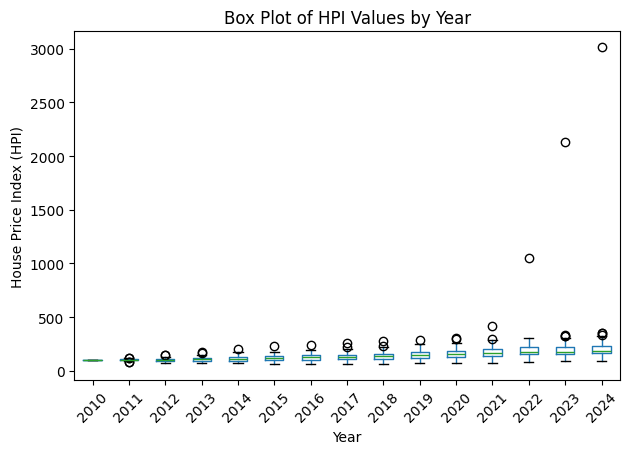

In [79]:
plot_hpi_boxplots_by_year(df_hpi)

In [80]:
from scipy.stats.mstats import winsorize

In [81]:
def round_and_winsorize_hpi(df_hpi, year_column='Year', limits=(0.05, 0.05)):
    """
    Rounds all HPI values to two decimals, then applies Winsorization per year.

    Parameters:
    - df_hpi: DataFrame with 'Year' column and HPI values per country
    - year_column: Name of the column containing years (default: 'Year')
    - limits: Tuple indicating proportion to cut from each tail (default: 10%)

    Returns:
    - DataFrame with rounded and Winsorized HPI values
    """

    # Step 1: Round all numeric values to 2 decimals
    df_rounded = df_hpi.copy()
    country_columns = [col for col in df_rounded.columns if col != year_column]
    df_rounded[country_columns] = df_rounded[country_columns].round(2)

    # Step 2: Apply Winsorization row by row
    df_winsorized = df_rounded.copy()

    for idx, row in df_rounded.iterrows():
        values = row[country_columns].values.astype(float)

        # Apply Winsorization only if enough valid values
        if np.count_nonzero(~np.isnan(values)) >= 4:
            winsorized = winsorize(values, limits=limits)
            df_winsorized.loc[idx, country_columns] = winsorized

    return df_winsorized

In [82]:
df_hpi_winsorized = round_and_winsorize_hpi(df_hpi)

<Figure size 1400x600 with 0 Axes>

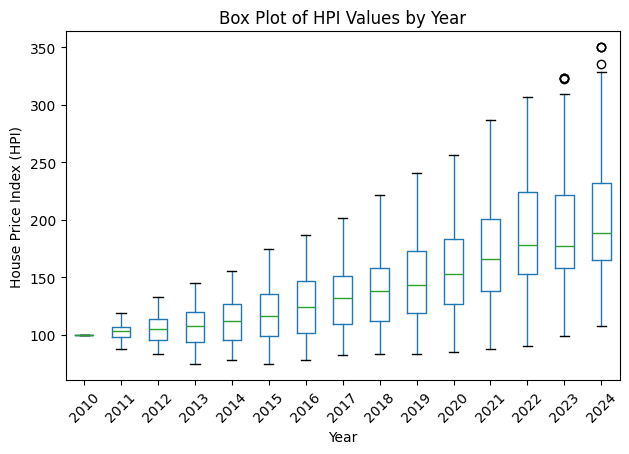

In [84]:
plot_hpi_boxplots_by_year(df_hpi_winsorized)

In [85]:
df_hpi_winsorized = round_and_winsorize_hpi(df_hpi_winsorized, limits=(0.078,0.078))

<Figure size 1400x600 with 0 Axes>

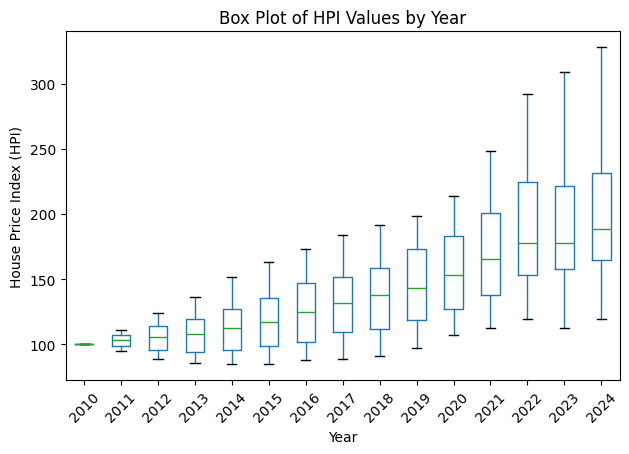

In [86]:
plot_hpi_boxplots_by_year(df_hpi_winsorized)

### Leverage The Law of Large Numbers
* Run the sampling process for each cluster, exclude one country of that cluster to compare

In [87]:
import random

In [88]:
def estimate_hpi_by_cluster_sampling(df_hpi, df_clusters, cluster_id,
                                     cluster_column='cluster', country_column='Country',
                                     year_column='Year', sample_size=30, n_samples=1000,
                                     plot=True, seed=None):
    """
    Estimates synthetic HPI values for a randomly excluded country from a selected cluster.

    Parameters:
    - df_hpi: DataFrame with HPI values (columns = countries, rows = years, plus 'Year' column)
    - df_clusters: DataFrame with country names and cluster assignments
    - cluster_id: Cluster number to use for sampling
    - cluster_column: Column name in df_clusters with cluster labels
    - country_column: Column name in df_clusters with country names
    - year_column: Column name in df_hpi with year values
    - sample_size: Size of each sample (default: 30)
    - n_samples: Number of samples to generate (default: 1000)
    - plot: Whether to show histograms for each year (default: True)
    - seed: Optional random seed for reproducibility

    Returns:
    - synthetic_hpi: dict with estimated HPI values per year
    - excluded_country: name of the country left out
    - actual_values: dict with real HPI values of the excluded country
    """

    if seed is not None:
        random.seed(seed)
        np.random.seed(seed)

    # Step 1: Get countries in the selected cluster that are present in the HPI DataFrame
    all_cluster_countries = df_clusters[df_clusters[cluster_column] == cluster_id][country_column].tolist()
    cluster_countries = [c for c in all_cluster_countries if c in df_hpi.columns]
    
    if len(cluster_countries) < 2:
        raise ValueError("Cluster must contain at least two countries present in HPI data to perform exclusion and sampling.")
    
    # Step 2: Randomly exclude one country from those present in HPI
    excluded_country = random.choice(cluster_countries)
    sampling_countries = [c for c in cluster_countries if c != excluded_country]

    print(f"🔍 Cluster {cluster_id} selected. Excluding country: {excluded_country}")
    print(f"📊 Sampling from countries: {sampling_countries}")

    # Step 3: Prepare output containers
    synthetic_hpi = {}
    actual_values = {}

    # Step 4: Iterate over each year
    for _, row in df_hpi.iterrows():
        year = row[year_column]

        # Get HPI values for sampling countries
        values = row[sampling_countries].dropna().values

        # Get actual value of excluded country
        actual_value = row.get(excluded_country, np.nan)
        actual_values[year] = actual_value

        if len(values) == 0:
            print(f"⚠️ No HPI data available for cluster peers in year {year}")
            synthetic_hpi[year] = np.nan
            continue

        # Print available HPI values for sampling
        print(f"\n📅 Year {year} - Available HPI values for sampling:")
        print(values)

        # Generate sampling distribution
        sample_means = []
        cumulative_means = []
        for i in range(n_samples):
            sample = np.random.choice(values, size=sample_size, replace=True)
            mean = np.mean(sample)
            sample_means.append(mean)
            cumulative_means.append(np.mean(sample_means))  # track convergence

        # Compute 95% confidence interval
        lower_bound = np.percentile(sample_means, 2.5)
        upper_bound = np.percentile(sample_means, 97.5)

        # Plot side-by-side: histogram + convergence
        fig, axes = plt.subplots(1, 2, figsize=(14, 4))

        # Histogram with confidence interval
        axes[0].hist(sample_means, bins=30, color='lightgreen', edgecolor='black')
        axes[0].axvline(actual_value, color='red', linestyle='--', label=f"Actual: {excluded_country}")
        axes[0].axvline(lower_bound, color='blue', linestyle=':', label='95% CI Lower')
        axes[0].axvline(upper_bound, color='blue', linestyle=':', label='95% CI Upper')
        axes[0].set_title(f"HPI Sampling Distribution - Year {year}")
        axes[0].set_xlabel("Sample Mean HPI")
        axes[0].set_ylabel("Frequency")
        axes[0].legend()
        axes[0].grid(True)

        # Convergence plot
        axes[1].plot(cumulative_means, color='purple')
        axes[1].axhline(np.mean(sample_means), color='gray', linestyle='--', label='Final Mean')
        axes[1].set_title("Mean Convergence Over Iterations")
        axes[1].set_xlabel("Iteration")
        axes[1].set_ylabel("Cumulative Mean")
        axes[1].legend()
        axes[1].grid(True)

        plt.tight_layout()
        plt.show()
        # Store synthetic HPI value
        synthetic_hpi[year] = np.mean(sample_means)

    return synthetic_hpi, excluded_country, actual_values

🔍 Cluster 0 selected. Excluding country: Russia
📊 Sampling from countries: ['Chile', 'Colombia', 'Hungary', 'India', 'Japan', 'South Korea']

📅 Year 2010.0 - Available HPI values for sampling:
[100. 100. 100. 100. 100. 100.]


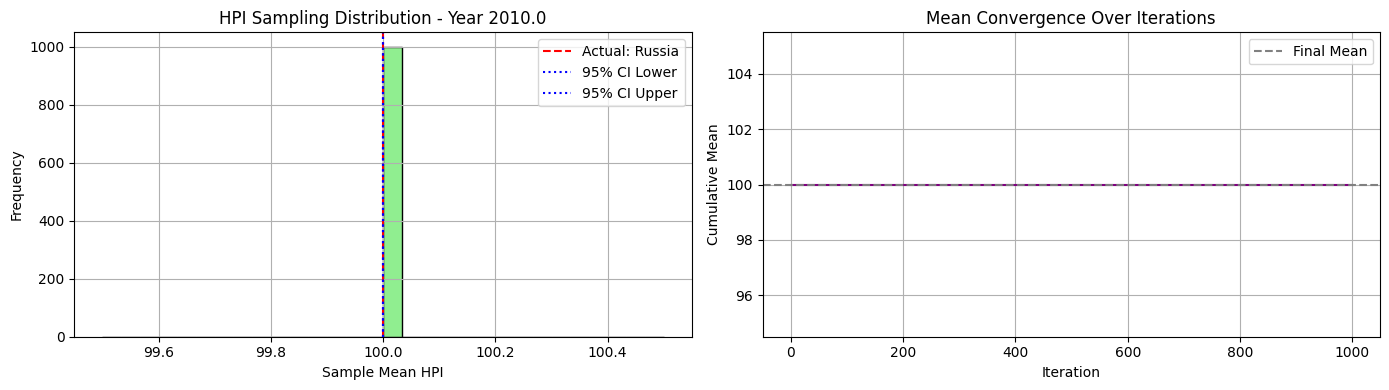


📅 Year 2011.0 - Available HPI values for sampling:
[110.52 107.89  96.56 110.52 100.07 105.23]


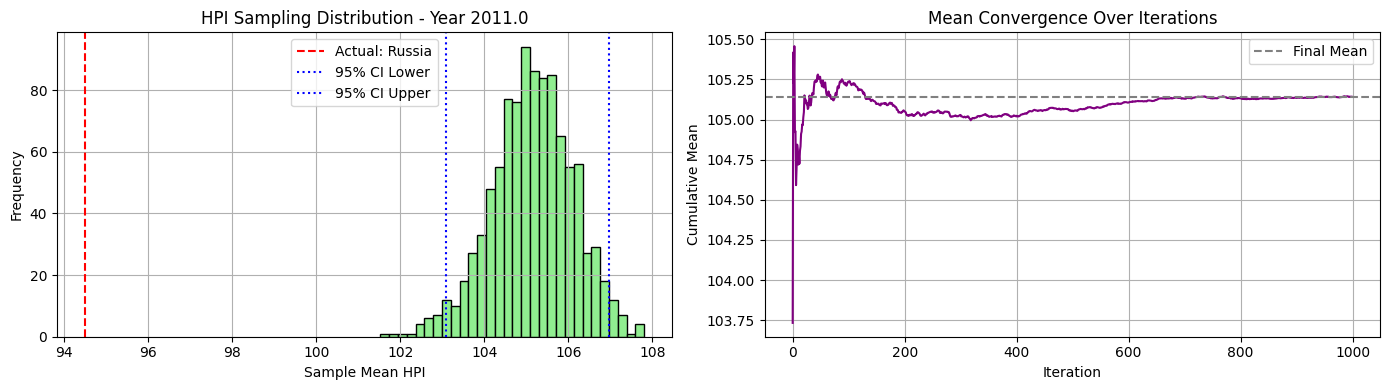


📅 Year 2012.0 - Available HPI values for sampling:
[124.02 118.79  92.98 124.02  99.19 108.25]


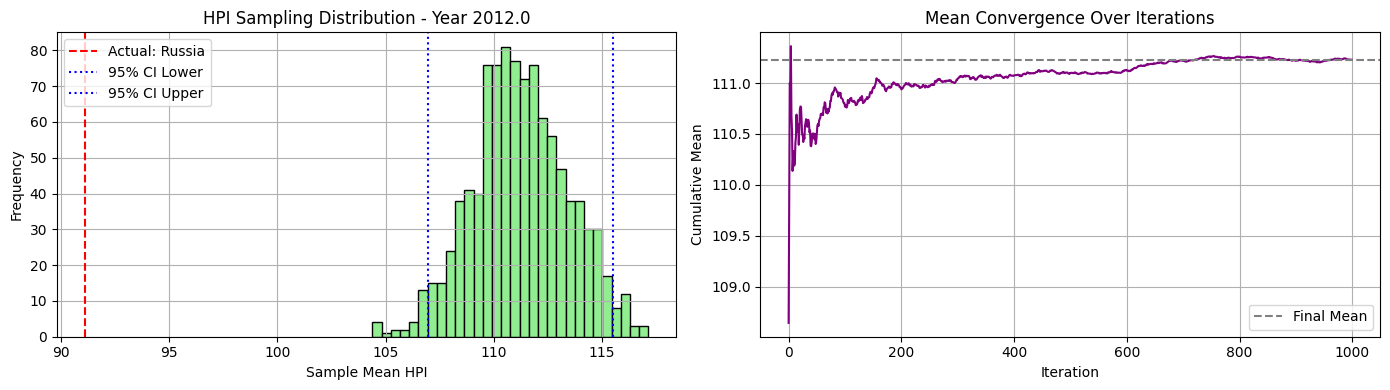


📅 Year 2013.0 - Available HPI values for sampling:
[136.52 130.06  90.58 136.52 100.81 107.8 ]


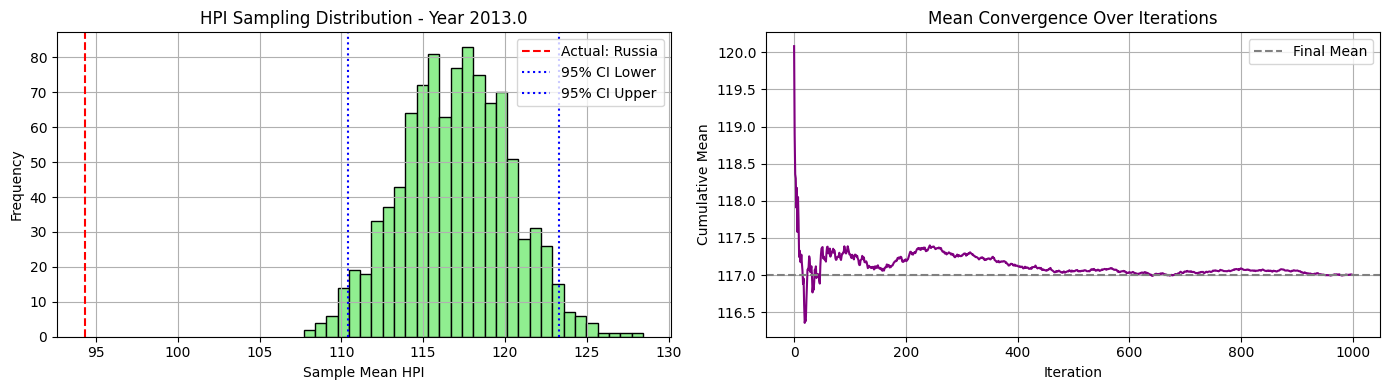


📅 Year 2014.0 - Available HPI values for sampling:
[151.67 140.75  94.37 151.67 102.38 109.43]


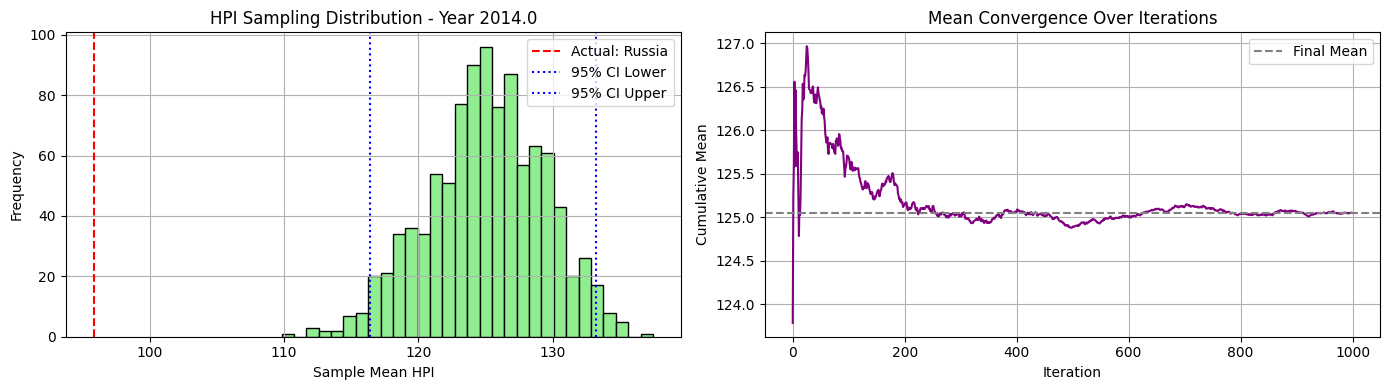


📅 Year 2015.0 - Available HPI values for sampling:
[162.89 152.93 106.75 162.89 104.86 113.08]


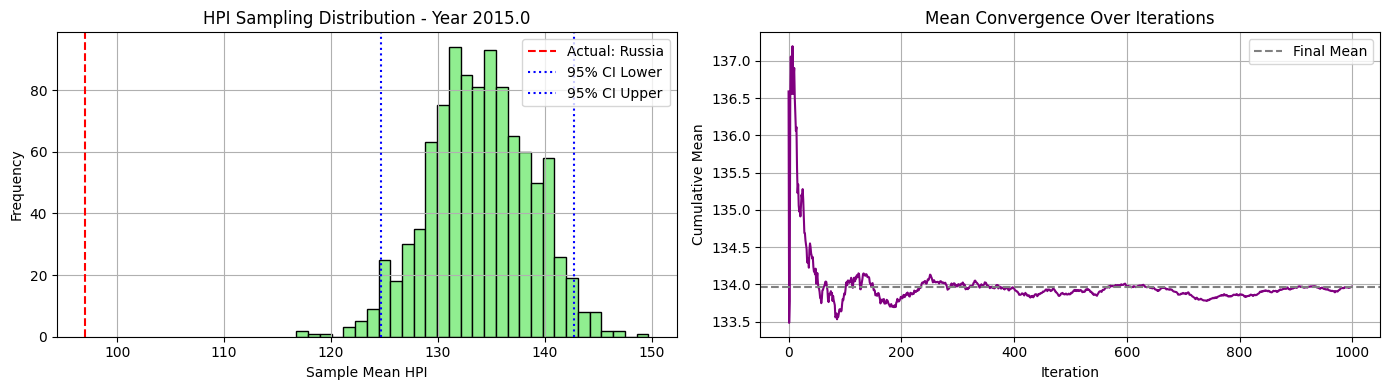


📅 Year 2016.0 - Available HPI values for sampling:
[172.75 167.48 121.03 172.75 107.18 116.09]


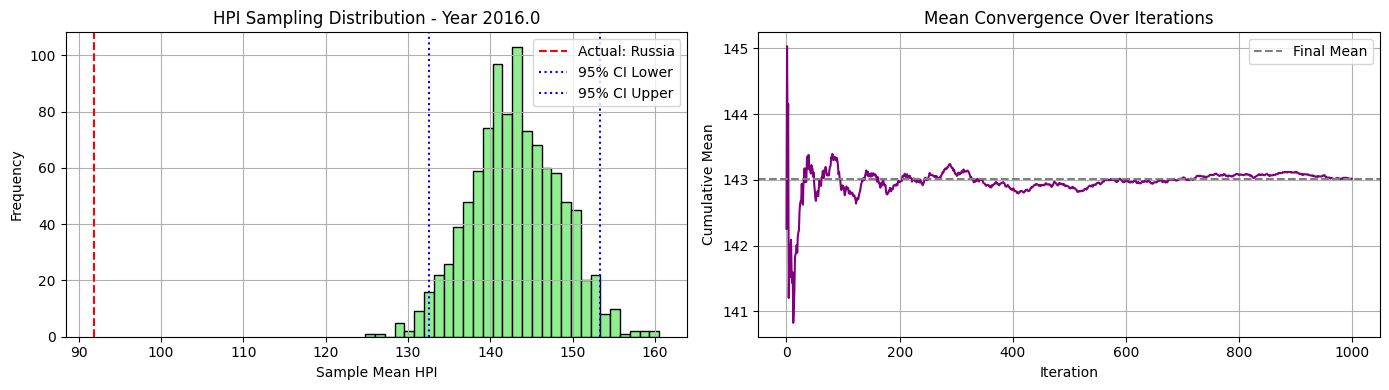


📅 Year 2017.0 - Available HPI values for sampling:
[183.99 178.56 135.84 183.99 109.91 117.6 ]


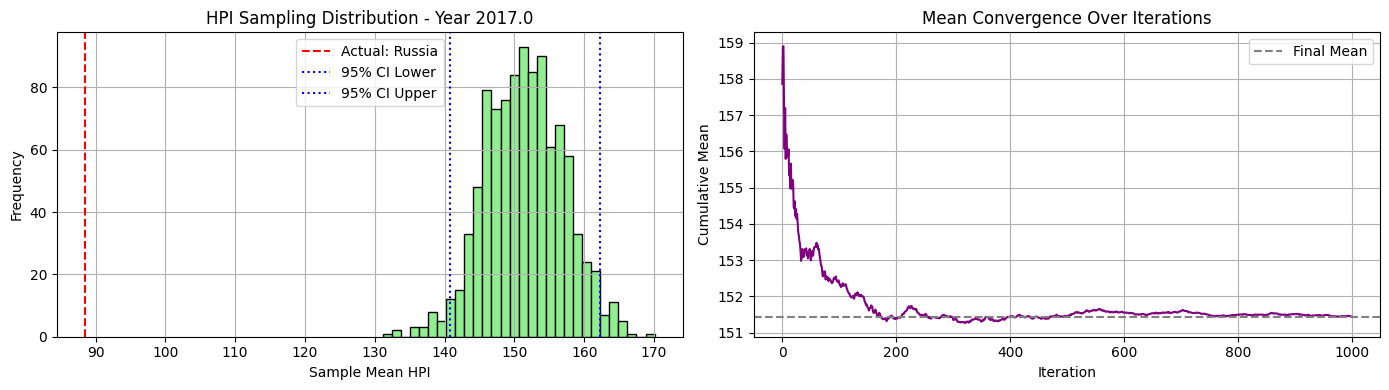


📅 Year 2018.0 - Available HPI values for sampling:
[191.85 188.24 155.3  191.85 112.04 120.22]


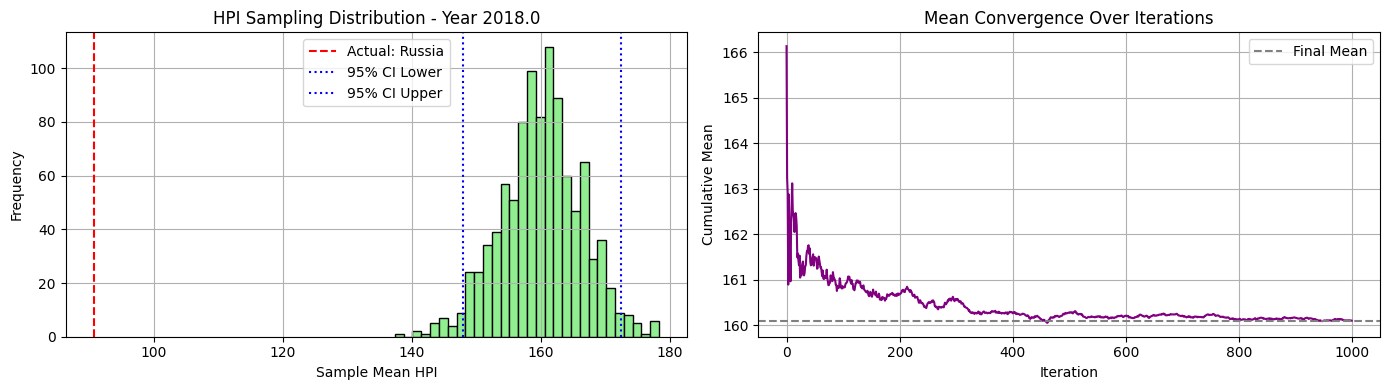


📅 Year 2019.0 - Available HPI values for sampling:
[198.37 198.37 181.64 198.37 113.84 121.93]


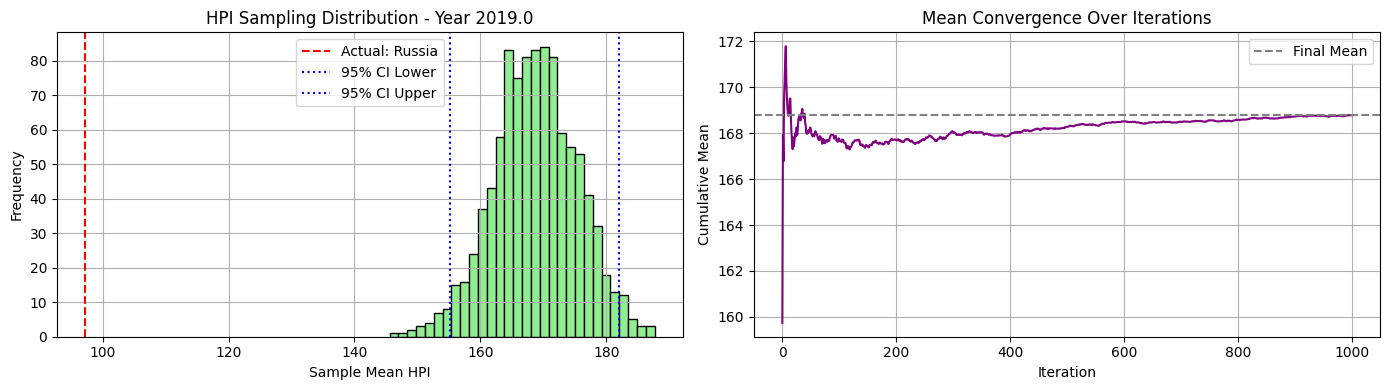


📅 Year 2020.0 - Available HPI values for sampling:
[213.74 203.12 190.63 213.74 113.93 126.56]


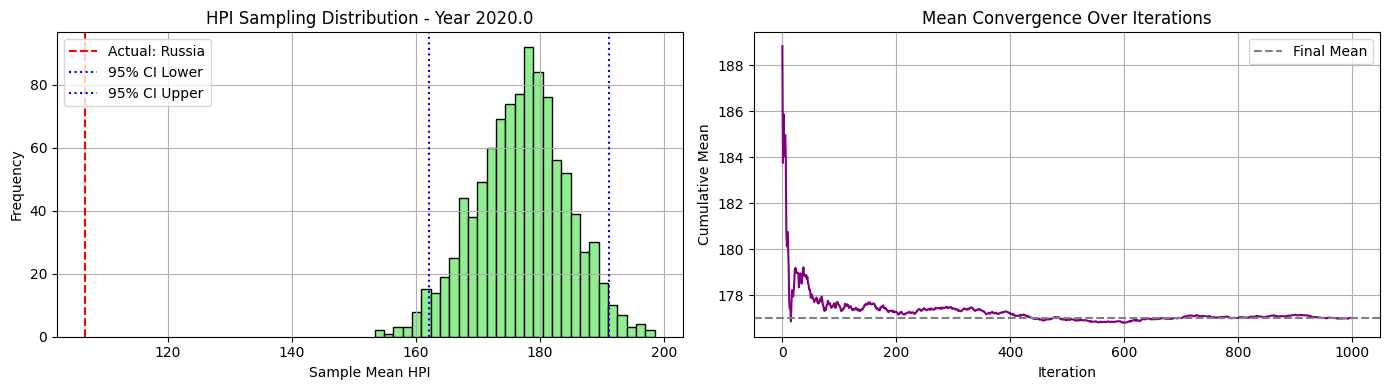


📅 Year 2021.0 - Available HPI values for sampling:
[248.26 214.9  222.1  248.26 120.7  143.73]


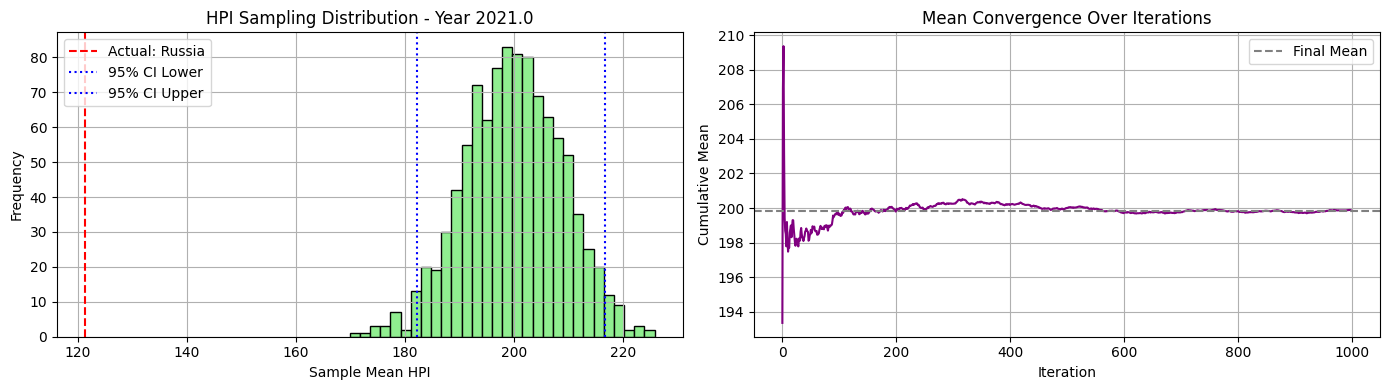


📅 Year 2022.0 - Available HPI values for sampling:
[292.18 230.   271.5  292.18 130.84 153.22]


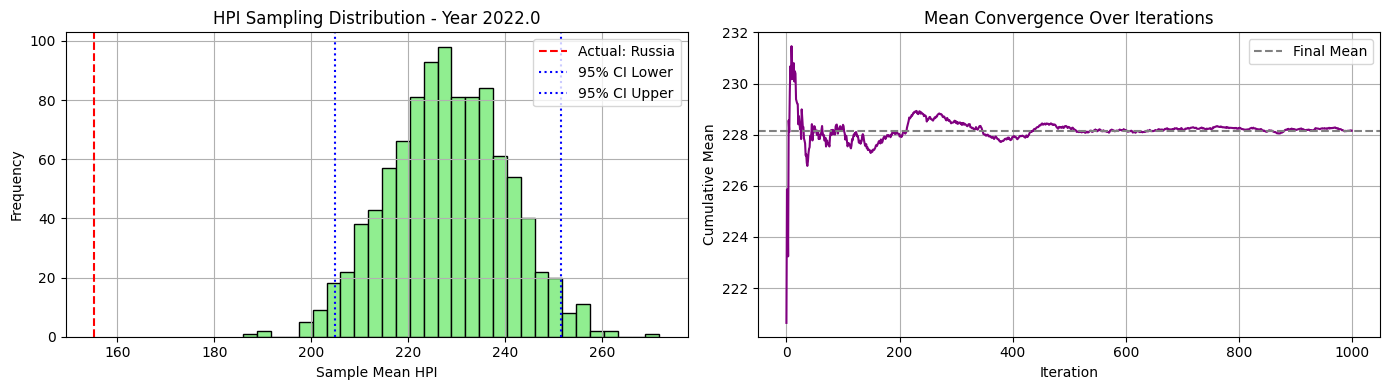


📅 Year 2023.0 - Available HPI values for sampling:
[309.37 245.75 290.98 309.37 134.8  143.99]


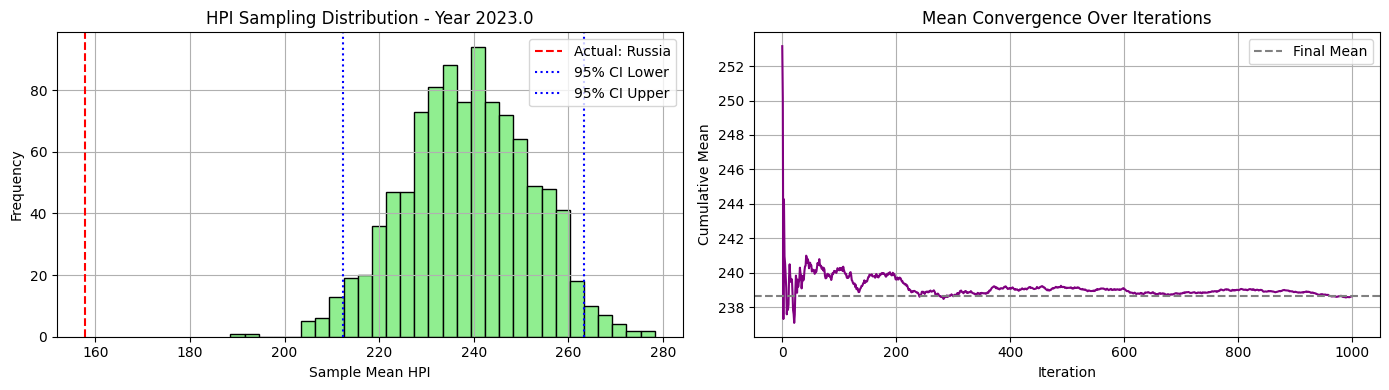


📅 Year 2024.0 - Available HPI values for sampling:
[328.24 269.02 328.1  328.24 138.61 142.46]


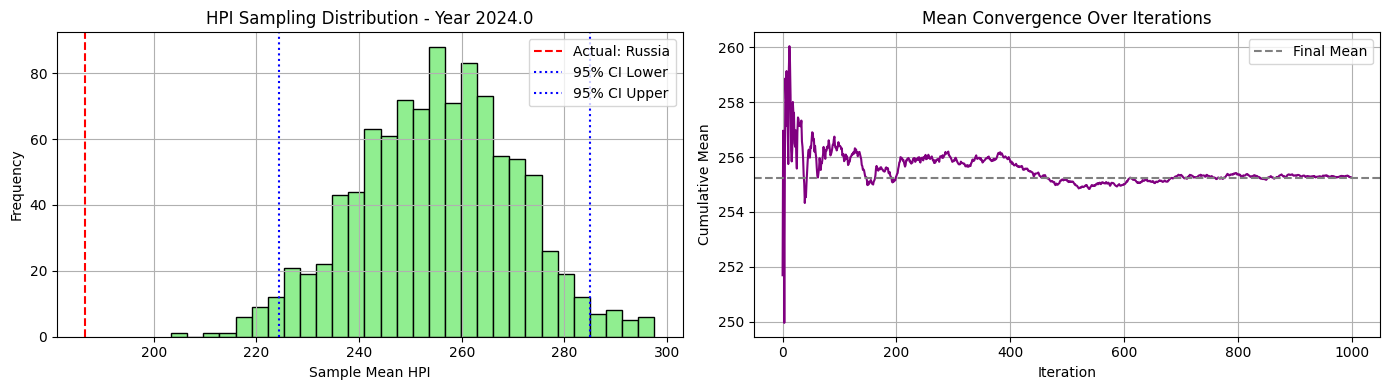

In [89]:
synthetic_01, excluded_01, actual_01 = estimate_hpi_by_cluster_sampling(df_hpi_winsorized, clusters_countries, cluster_id=0, seed=42)

🔍 Cluster 1 selected. Excluding country: Croatia
📊 Sampling from countries: ['Austria', 'Belgium', 'Bulgaria', 'Cyprus', 'Estonia', 'Finland', 'Greece', 'Ireland', 'Latvia', 'Lithuania', 'Luxembourg', 'Malta', 'New Zealand', 'Portugal', 'Slovakia', 'Slovenia']

📅 Year 2010.0 - Available HPI values for sampling:
[100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100.
 100. 100.]


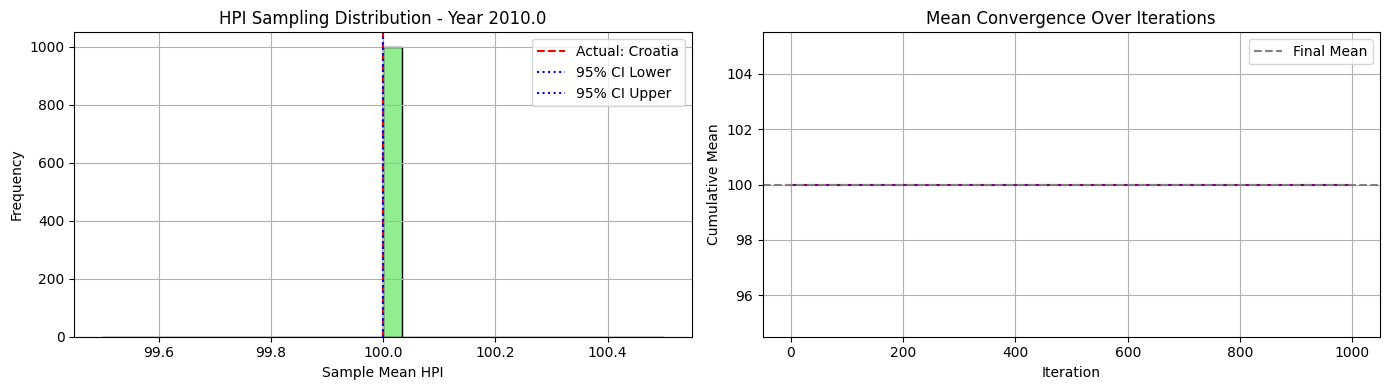


📅 Year 2011.0 - Available HPI values for sampling:
[104.22 103.58  94.49  96.68 108.47 103.17  94.53  94.49 110.42 106.6
 103.68  98.63 100.75  95.1   98.46 102.72]


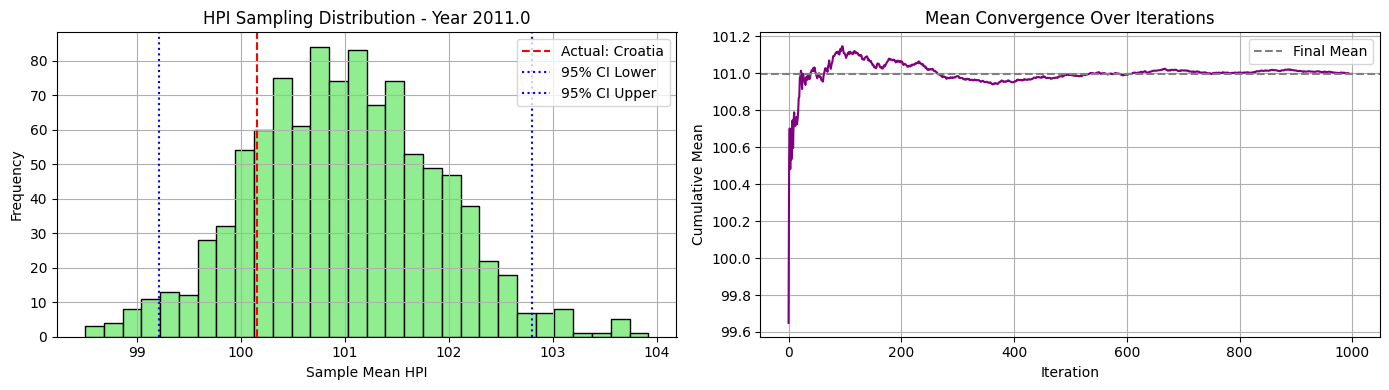


📅 Year 2012.0 - Available HPI values for sampling:
[117.13 106.02  92.69  91.54 116.34 105.64  88.37  88.37 113.71 106.36
 108.03 101.62 105.25  88.37  95.73  95.63]


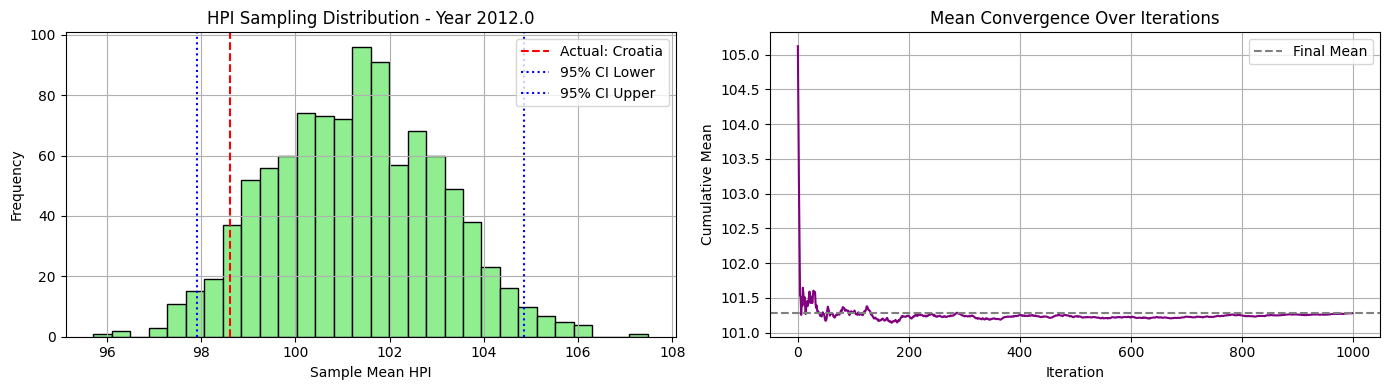


📅 Year 2013.0 - Available HPI values for sampling:
[122.59 107.59  90.65  85.58 128.77 106.87  85.58  85.58 121.5  107.65
 113.42 101.21 114.59  86.7   96.53  90.62]


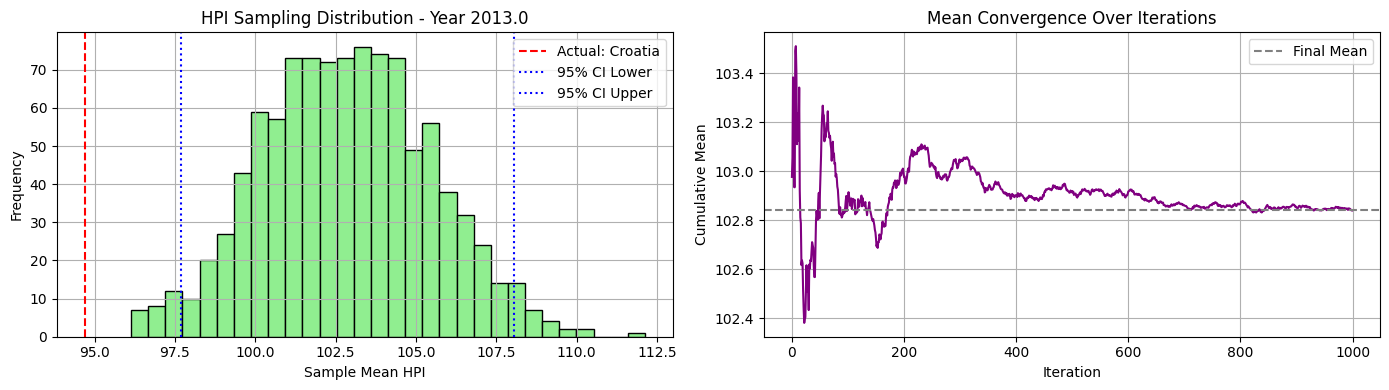


📅 Year 2014.0 - Available HPI values for sampling:
[126.79 107.22  91.95  84.64 146.41 106.5   84.64  84.66 128.78 114.57
 118.39 103.79 122.03  90.38  97.8   84.64]


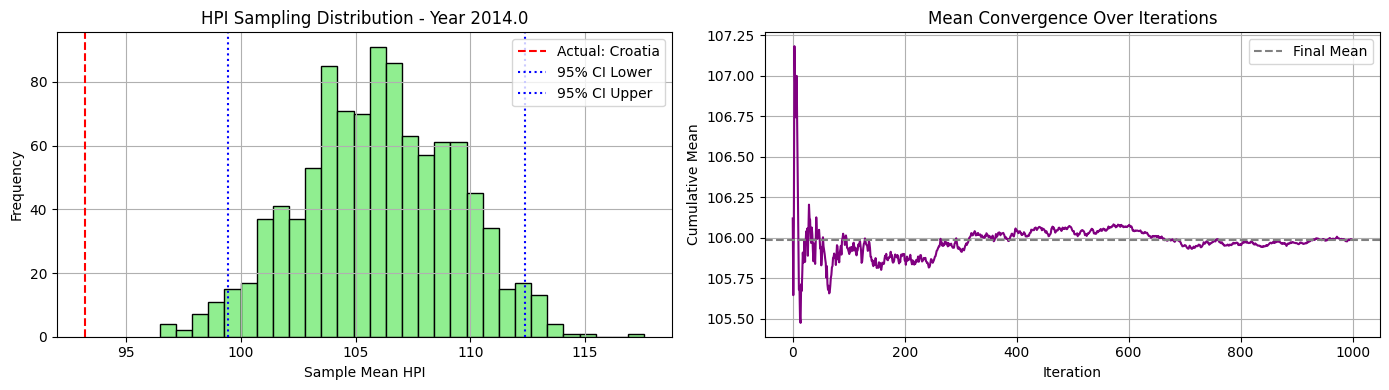


📅 Year 2015.0 - Available HPI values for sampling:
[132.06 109.17  94.51  84.67 156.46 106.5   84.67  94.36 124.46 118.76
 124.78 109.83 137.18  93.15 103.    85.32]


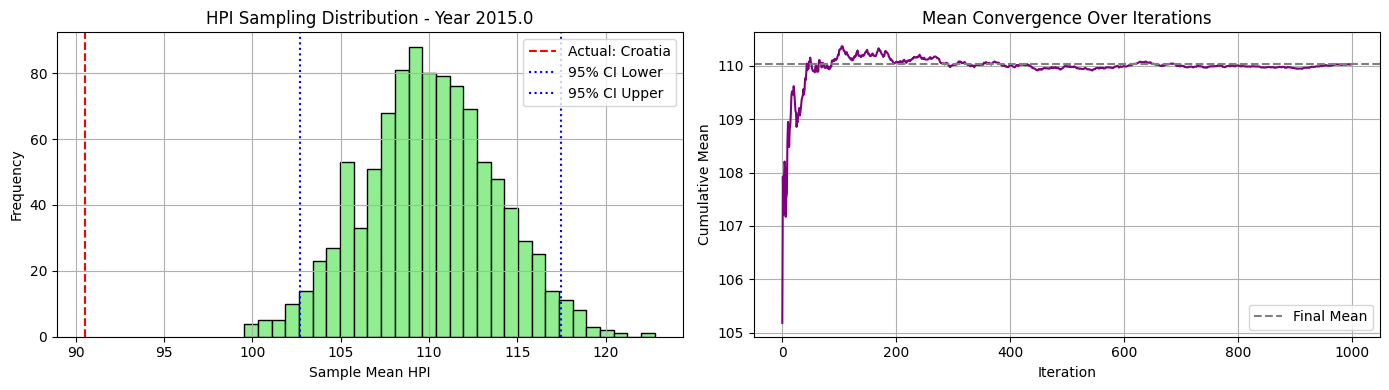


📅 Year 2016.0 - Available HPI values for sampling:
[141.76 111.72 101.15  88.1  163.86 107.86  88.1  101.42 135.02 125.16
 132.28 115.82 156.62  99.78 109.87  88.1 ]


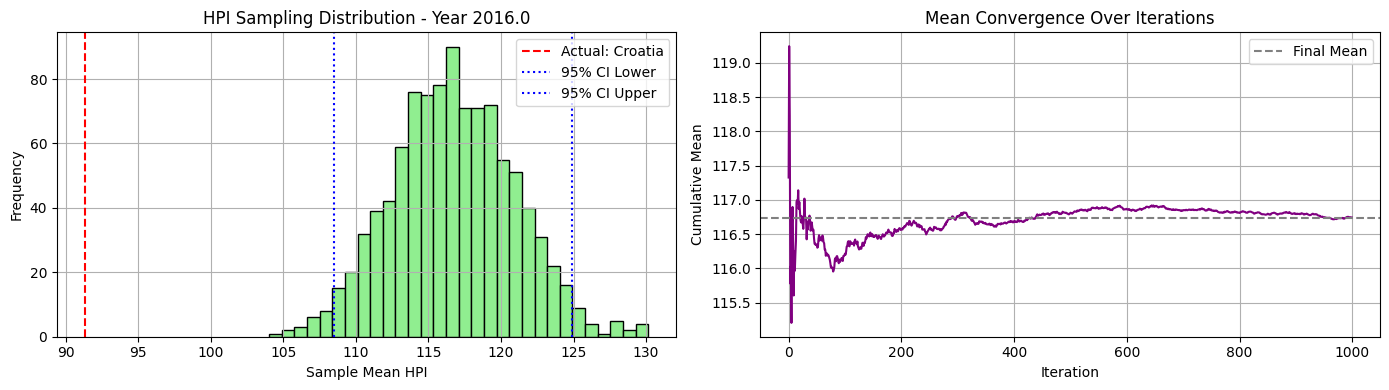


📅 Year 2017.0 - Available HPI values for sampling:
[147.08 115.66 109.91  88.54 172.91 109.02  88.54 112.44 146.87 136.34
 139.69 121.94 166.8  108.99 116.3   95.38]


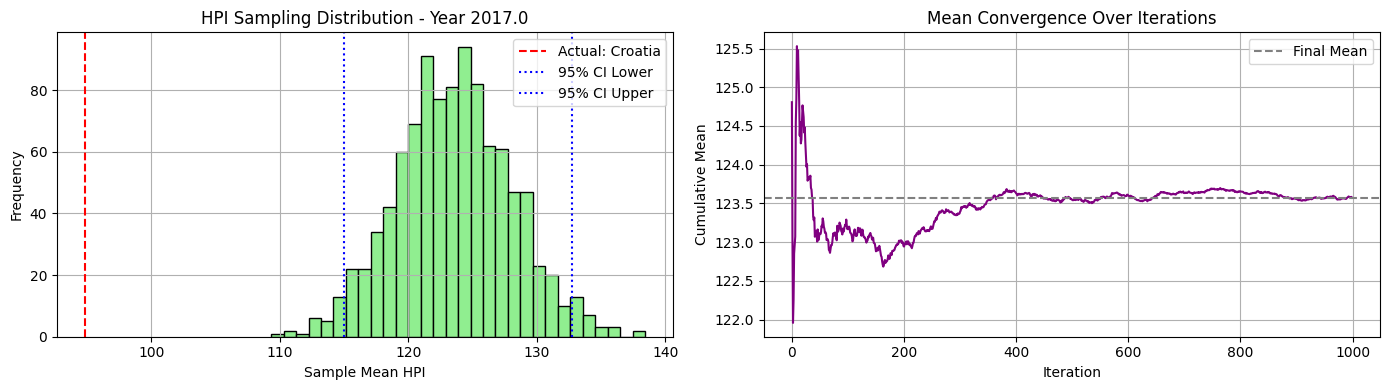


📅 Year 2018.0 - Available HPI values for sampling:
[157.24 119.16 117.15  90.72 183.13 110.06  90.72 123.96 160.92 146.29
 149.55 129.02 172.8  120.19 124.97 103.7 ]


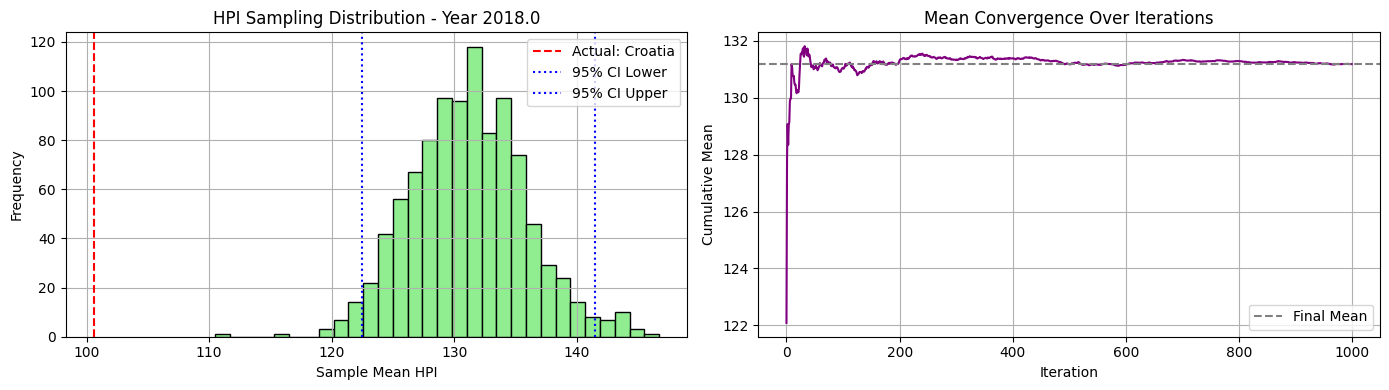


📅 Year 2019.0 - Available HPI values for sampling:
[163.43 123.62 124.2   97.25 195.98 110.52  97.25 126.85 175.33 156.3
 164.68 136.9  178.19 132.16 136.39 110.65]


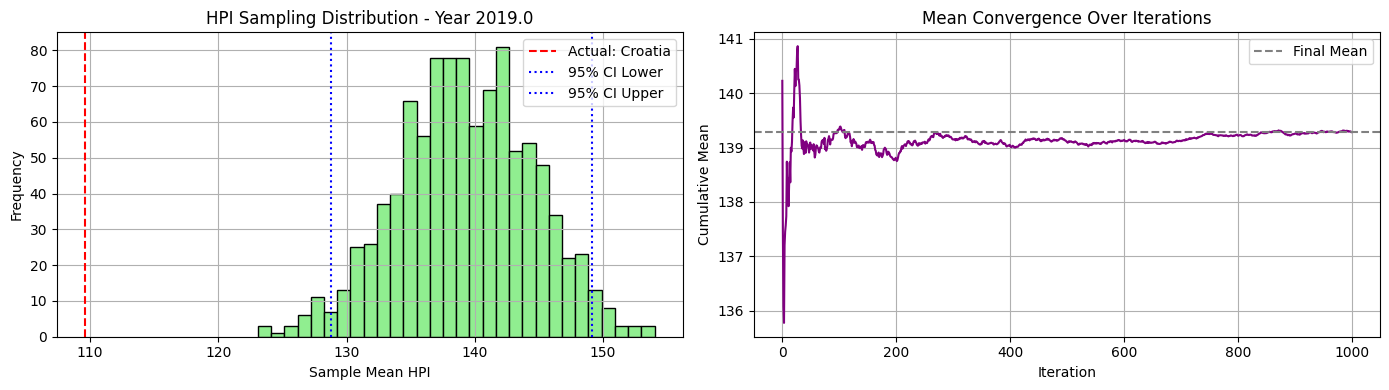


📅 Year 2020.0 - Available HPI values for sampling:
[174.92 128.92 129.87 106.71 207.78 112.49 106.71 127.24 181.42 167.66
 188.57 141.54 196.31 143.75 149.36 115.74]


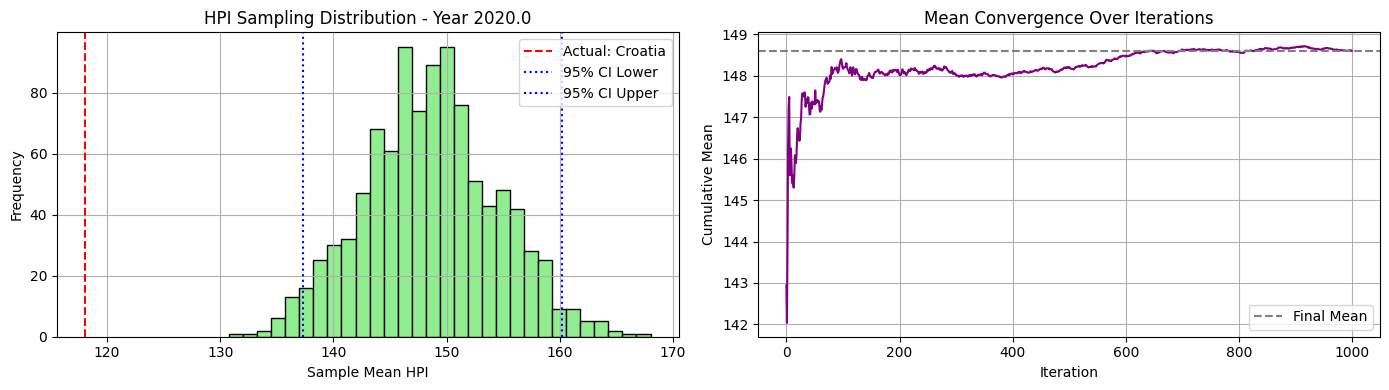


📅 Year 2021.0 - Available HPI values for sampling:
[195.48 137.52 141.14 112.34 239.04 117.62 112.34 137.77 201.18 194.58
 214.81 148.74 248.26 157.27 158.94 129.1 ]


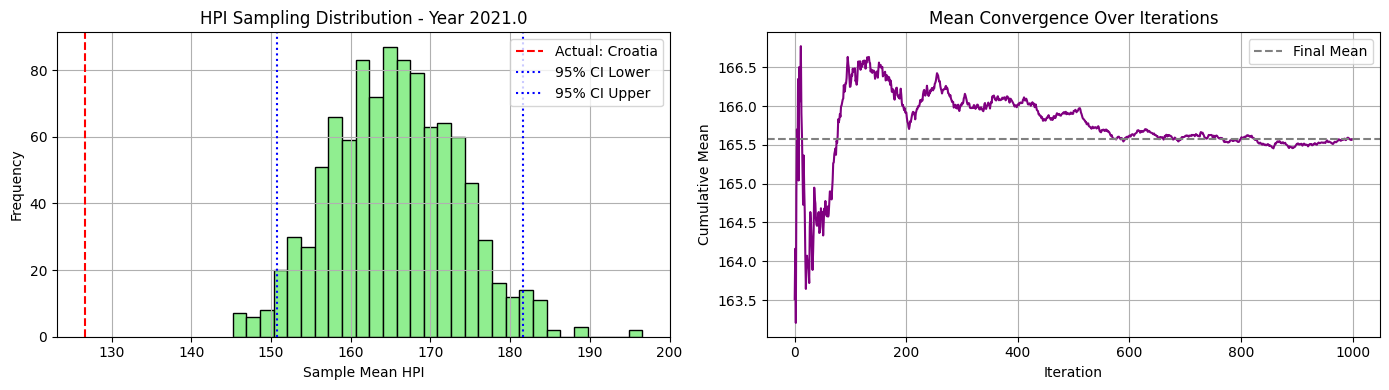


📅 Year 2022.0 - Available HPI values for sampling:
[215.62 145.12 160.59 118.98 292.18 118.98 118.98 154.73 229.01 231.64
 235.34 158.62 249.69 177.14 180.7  148.16]


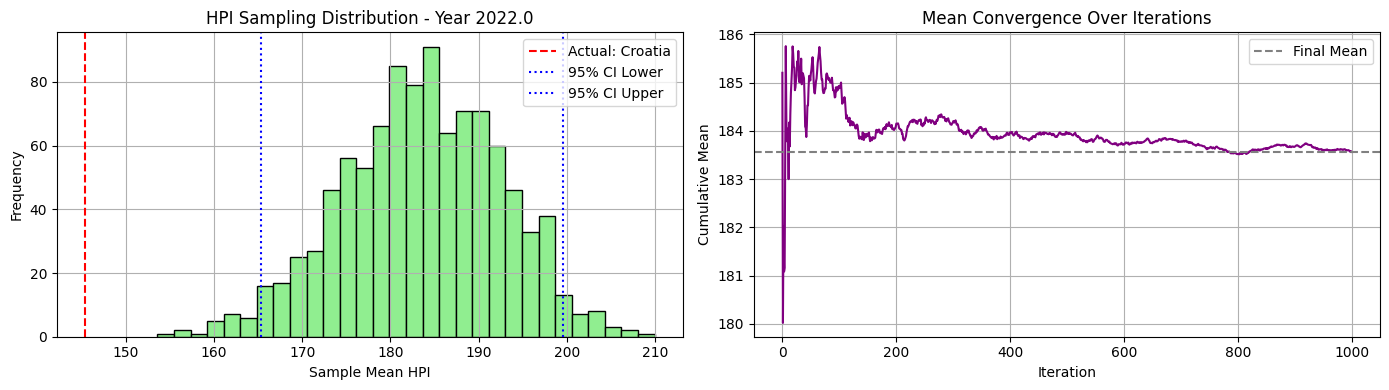


📅 Year 2023.0 - Available HPI values for sampling:
[212.08 148.52 176.43 112.27 309.37 112.27 112.27 159.48 237.56 254.38
 214.   168.5  233.54 191.66 180.36 158.88]


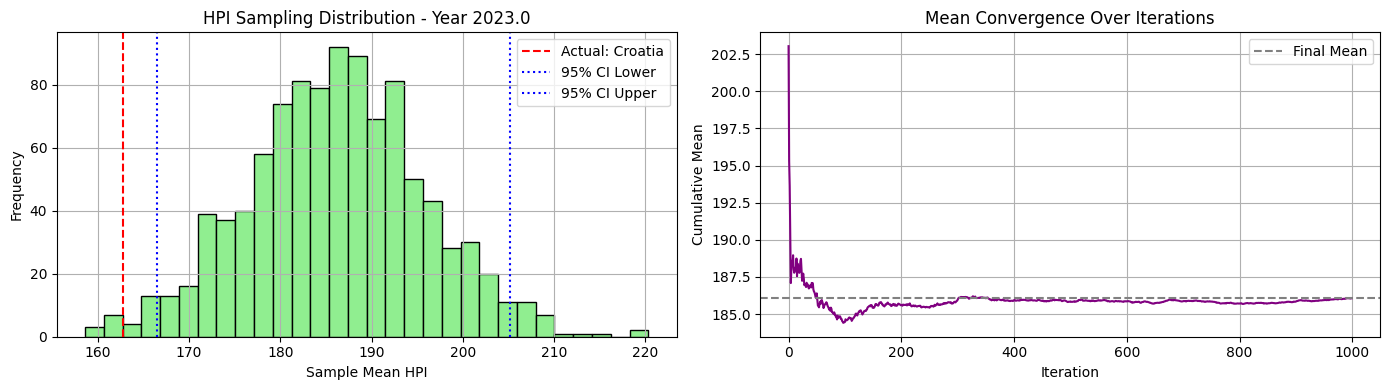


📅 Year 2024.0 - Available HPI values for sampling:
[207.62 153.31 205.53 119.1  328.24 119.1  119.1  173.07 247.54 279.12
 202.74 179.35 233.68 209.06 187.15 170.56]


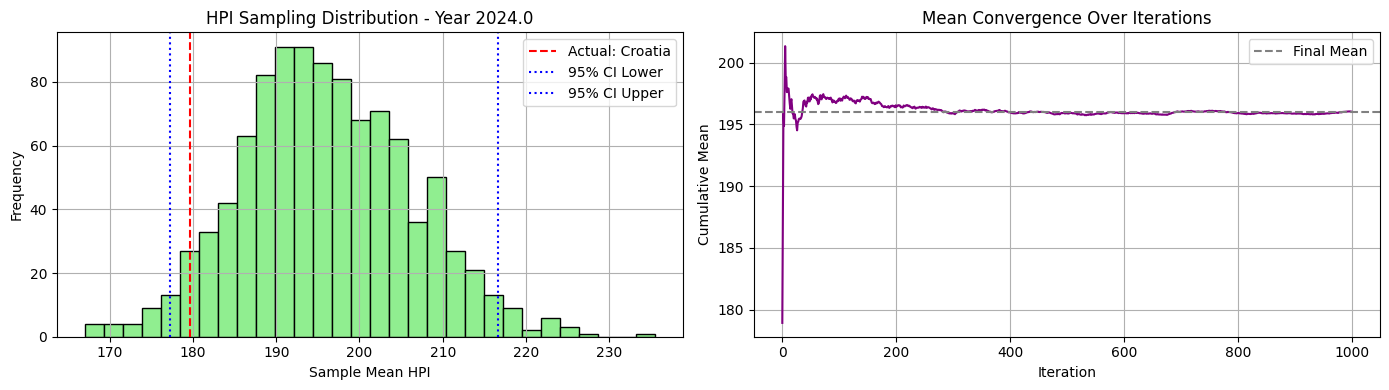

In [90]:
synthetic_02, excluded_02, actual_02 = estimate_hpi_by_cluster_sampling(df_hpi_winsorized, clusters_countries, cluster_id=1, seed=42)

🔍 Cluster 2 selected. Excluding country: South Africa
📊 Sampling from countries: ['Australia', 'Brazil', 'Canada', 'Czech Republic', 'Denmark', 'France', 'Germany', 'Iceland', 'Israel', 'Italy', 'Malaysia', 'Mexico', 'Netherlands', 'Norway', 'Peru', 'Philippines', 'Poland', 'Romania', 'Serbia', 'Singapore', 'Spain', 'Sweden', 'Switzerland', 'Thailand', 'Turkey', 'United Kingdom', 'USA']

📅 Year 2010.0 - Available HPI values for sampling:
[100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100.
 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100.]


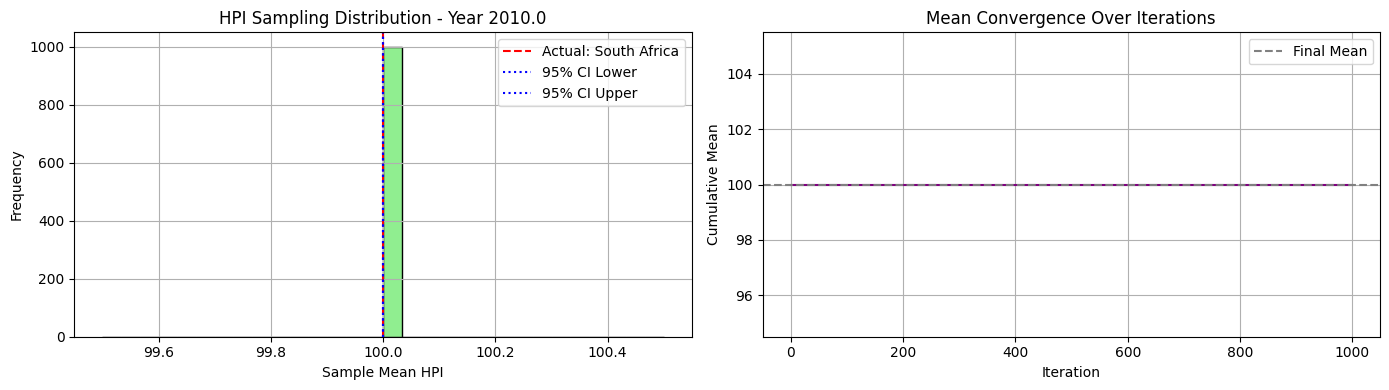


📅 Year 2011.0 - Available HPI values for sampling:
[ 97.84 110.52 105.75 100.02  98.29 105.69 102.42 105.5  110.52 101.36
 109.83 105.8   98.02 108.01 110.52 105.57 100.08  94.49  97.62 109.46
  94.49 102.58 107.51 104.26 108.8   98.54  97.24]


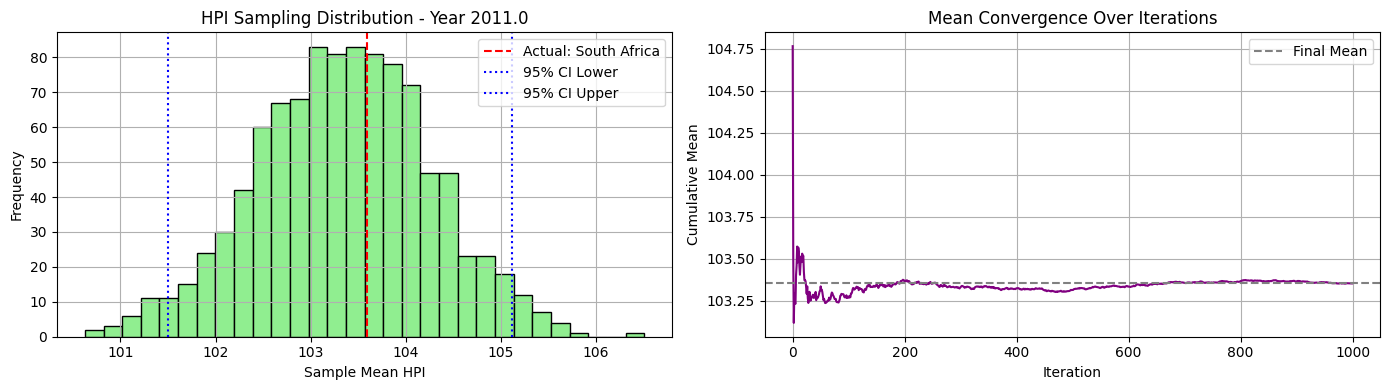


📅 Year 2012.0 - Available HPI values for sampling:
[ 97.53 124.02 110.62  98.56  95.67 105.11 105.48 112.38 114.1   98.77
 124.02 109.17  91.44 115.34 124.02 114.94  96.58  88.37  95.68 112.02
  88.37 103.86 113.72 107.63 120.68  98.92 101.82]


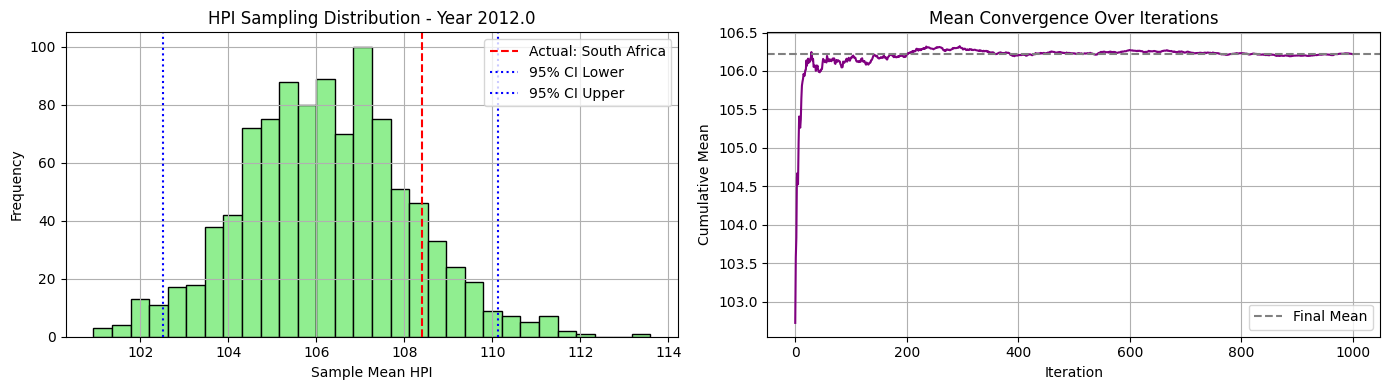


📅 Year 2013.0 - Available HPI values for sampling:
[103.99 136.52 112.76  98.58  99.37 103.13 108.68 119.18 124.45  92.38
 136.52 114.75  85.95 119.98 136.52 127.86  92.35  85.58  90.62 115.56
  85.58 109.22 118.3  115.99 134.46 101.46 111.83]


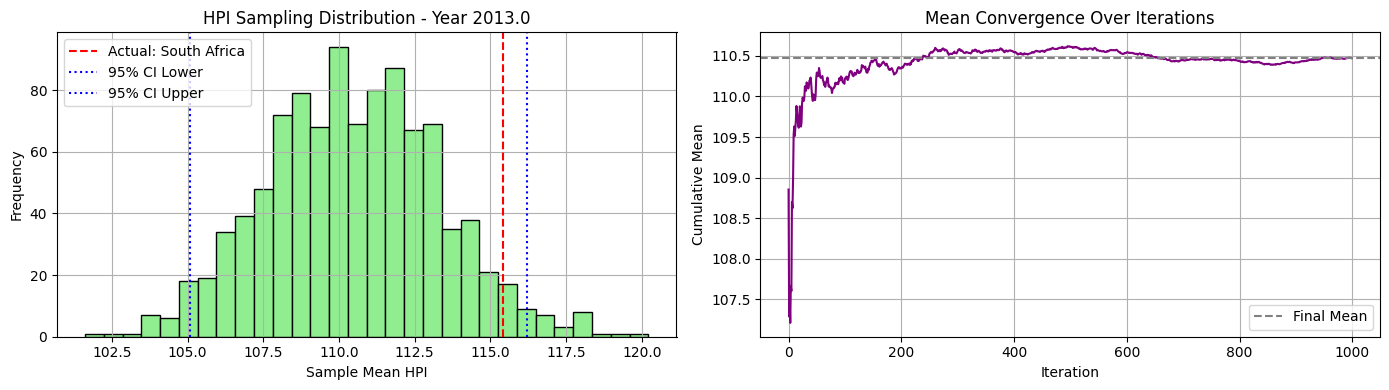


📅 Year 2014.0 - Available HPI values for sampling:
[113.41 151.67 118.86 101.   103.12 101.58 111.85 128.94 132.36  88.02
 151.67 119.64  86.66 123.24 151.67 142.76  93.27  84.64  95.77 112.25
  84.64 119.52 121.46 127.07 151.25 109.6  118.88]


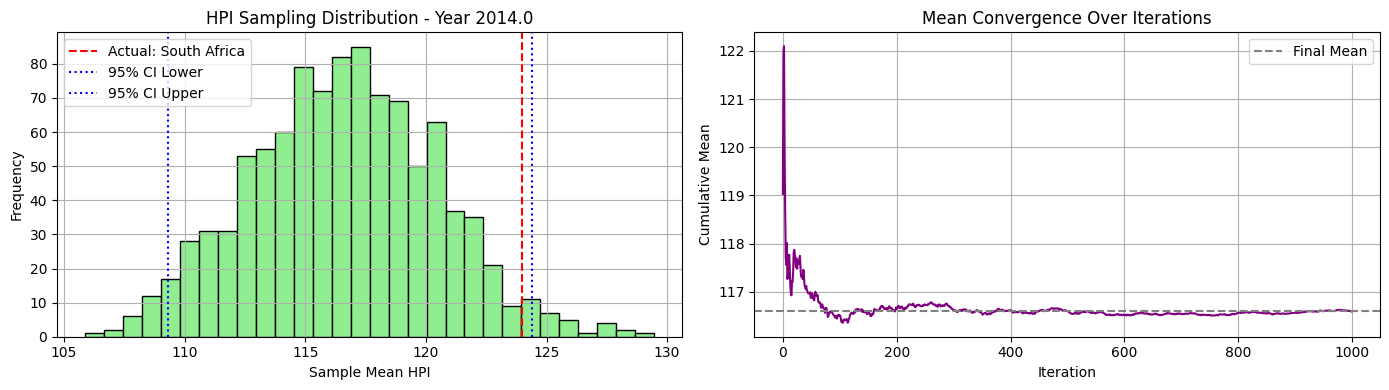


📅 Year 2015.0 - Available HPI values for sampling:
[123.65 156.16 128.43 105.01 110.29 100.22 117.12 139.74 140.12  84.67
 162.89 129.39  89.69 130.76 162.89 157.04  94.69  84.67  99.5  107.92
  84.67 135.2  124.08 136.   162.89 116.12 125.18]


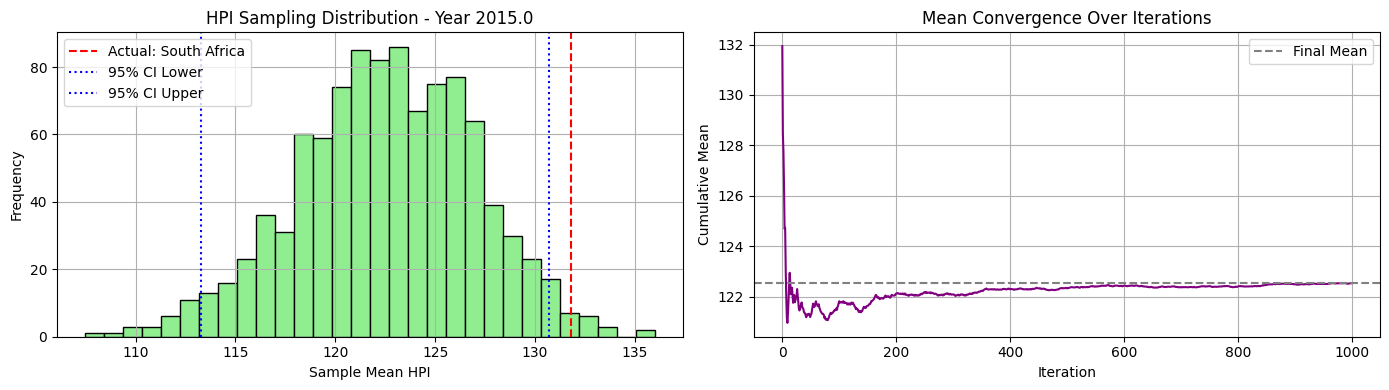


📅 Year 2016.0 - Available HPI values for sampling:
[130.44 151.94 148.66 112.52 115.5  101.25 125.93 154.59 150.56  88.1
 172.75 138.82  94.43 139.95 164.18 172.75  96.44  88.91 110.62 104.55
  88.1  146.34 124.32 142.4  172.75 124.27 131.88]


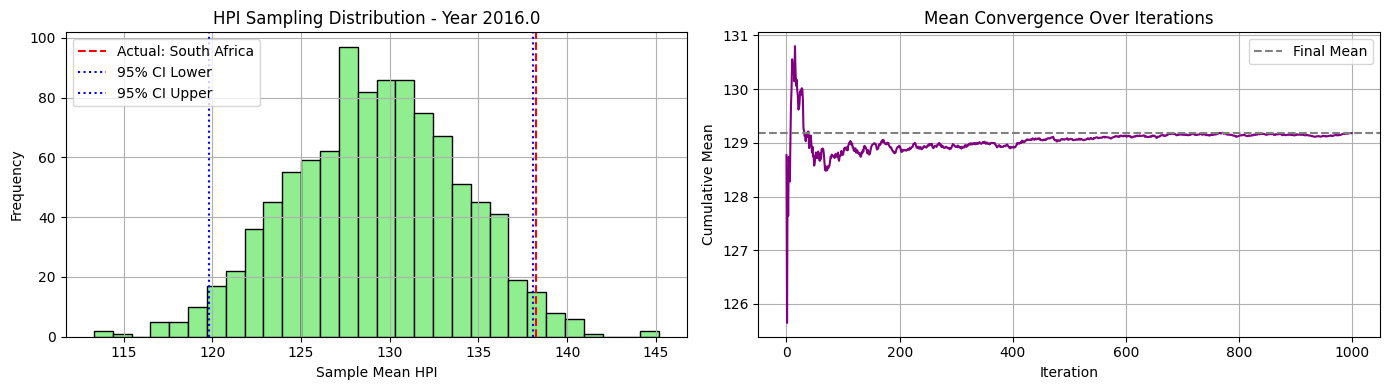


📅 Year 2017.0 - Available HPI values for sampling:
[141.34 149.02 172.3  125.7  120.63 104.46 133.62 183.99 156.44  88.54
 183.99 149.69 102.06 146.91 168.   178.82 100.16  93.93 115.3  103.4
  88.54 156.06 125.42 146.48 183.99 129.93 139.61]


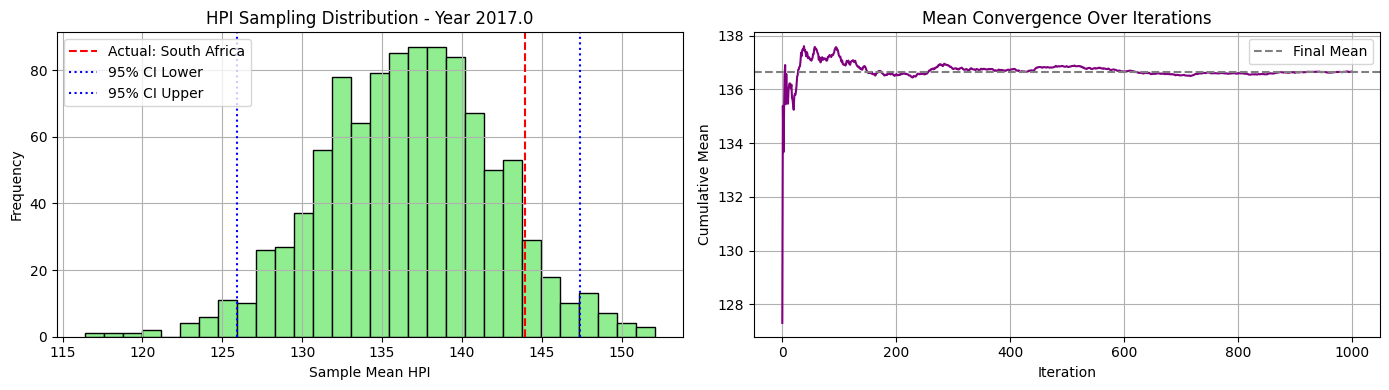


📅 Year 2018.0 - Available HPI values for sampling:
[139.3  149.81 178.24 136.52 126.31 107.52 142.52 191.85 155.14  90.72
 191.85 162.97 111.57 149.04 168.42 183.82 106.75  99.37 123.06 111.46
  90.72 154.6  129.16 153.9  191.85 134.04 147.35]


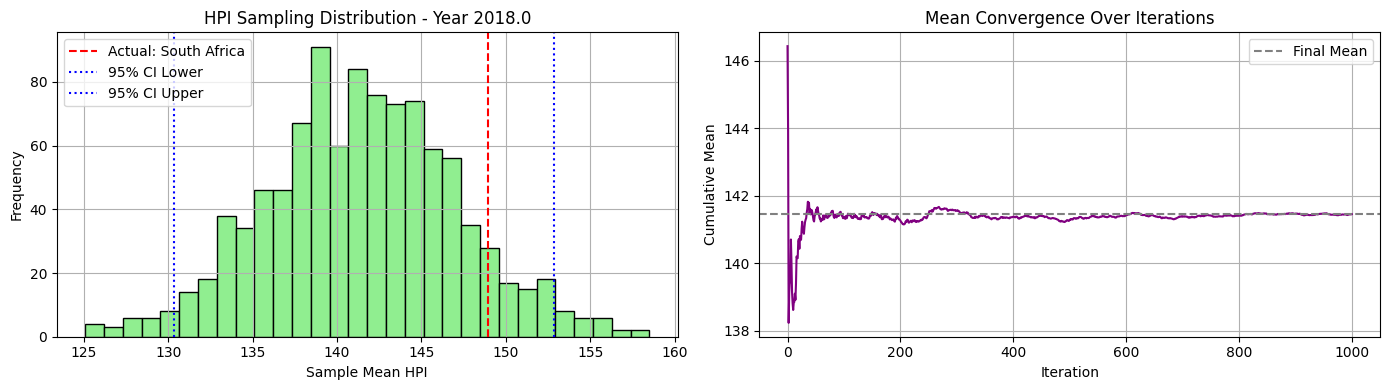


📅 Year 2019.0 - Available HPI values for sampling:
[133.64 155.06 179.4  149.02 129.62 111.1  150.75 198.37 158.06  97.25
 196.06 176.92 119.62 152.73 172.03 195.26 116.01 102.72 135.77 113.98
  97.25 158.44 133.99 155.1  198.37 135.37 153.14]


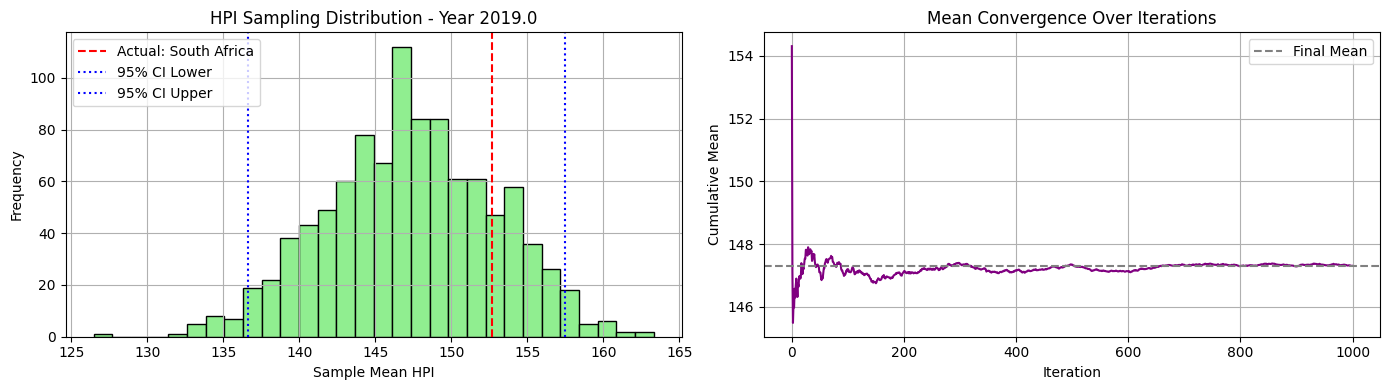


📅 Year 2020.0 - Available HPI values for sampling:
[140.85 166.92 190.73 161.56 136.24 116.89 162.48 213.74 162.9  106.71
 198.37 187.18 129.21 159.24 173.67 213.74 128.18 107.53 149.28 115.8
 106.71 165.09 137.31 160.6  213.74 139.24 163.52]


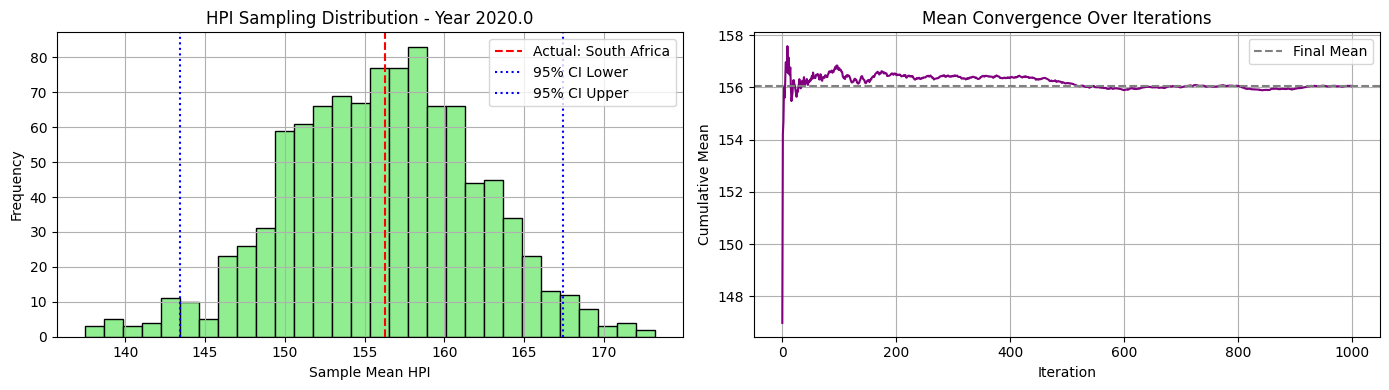


📅 Year 2021.0 - Available HPI values for sampling:
[165.39 180.02 214.88 193.46 152.2  124.38 181.28 248.26 176.65 112.34
 200.69 201.94 147.93 175.91 173.6  211.74 139.92 112.34 166.04 125.04
 112.34 181.79 145.16 164.23 248.26 150.58 188.56]


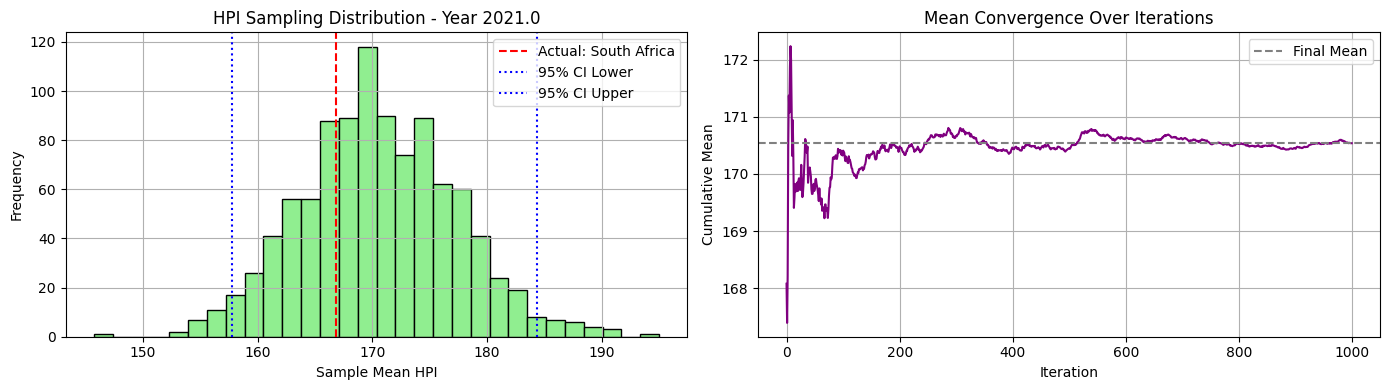


📅 Year 2022.0 - Available HPI values for sampling:
[179.02 185.16 235.32 226.15 151.49 132.1  190.42 292.18 207.16 118.98
 207.75 219.93 167.57 185.13 172.65 223.73 156.43 120.29 191.49 137.74
 118.98 188.27 154.42 169.16 292.18 164.55 213.  ]


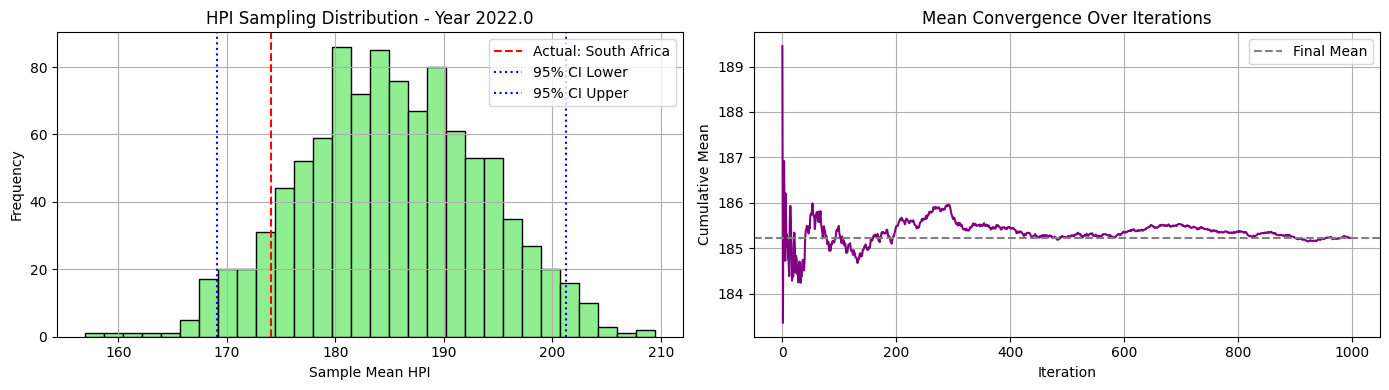


📅 Year 2023.0 - Available HPI values for sampling:
[178.65 191.27 221.05 222.4  151.24 131.52 174.25 309.37 214.23 112.27
 216.19 243.89 164.36 184.12 175.16 248.04 170.23 124.06 209.99 148.01
 112.27 178.36 157.81 174.79 309.37 165.   221.72]


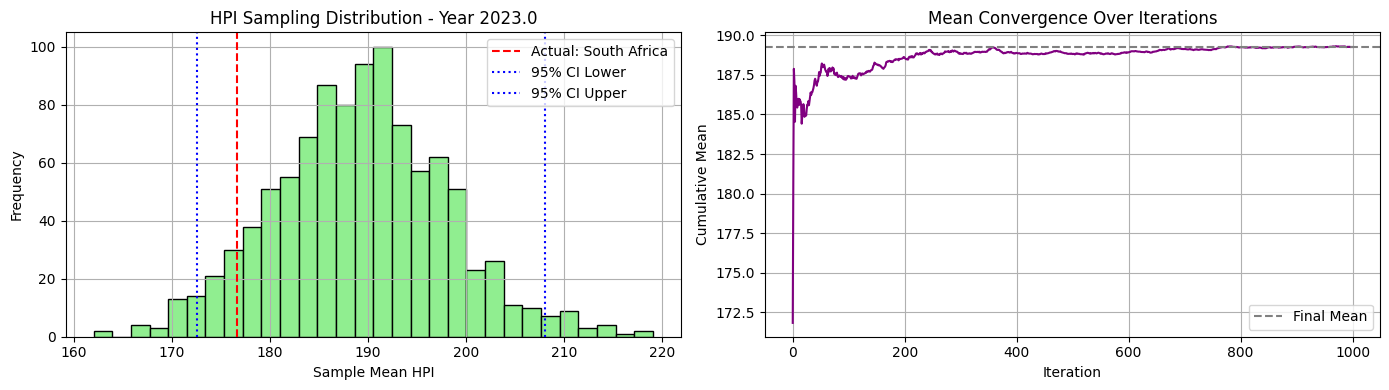


📅 Year 2024.0 - Available HPI values for sampling:
[192.53 203.78 217.35 233.42 156.73 126.68 171.5  328.24 224.54 119.1
 225.06 266.38 177.7  189.05 175.38 256.03 195.72 130.34 220.7  155.12
 119.1  178.49 160.56 178.06 328.24 166.38 231.23]


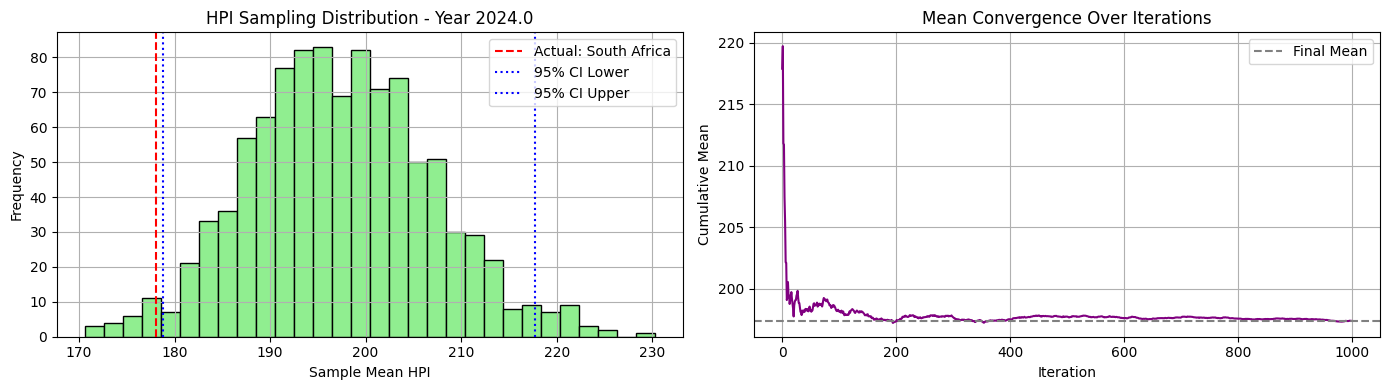

In [91]:
synthetic_03, excluded_03, actual_03 = estimate_hpi_by_cluster_sampling(df_hpi_winsorized, clusters_countries, cluster_id=2, seed=42)

### Compute metrics
* Compute MSE from synthetic data versus the real one from the country excluded
* Compute MAE from synthetic data versus the real one from the country excluded

In [92]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

In [93]:
def compute_global_mse_mae(synthetic_dicts, actual_dicts):
    """
    Computes global MSE and MAE across multiple synthetic vs. actual HPI dictionaries.

    Parameters:
    - synthetic_dicts: list of dicts with synthetic HPI values per year
    - actual_dicts: list of dicts with actual HPI values per year

    Returns:
    - mse: Mean Squared Error
    - mae: Mean Absolute Error
    """

    y_true = []
    y_pred = []

    for synth, actual in zip(synthetic_dicts, actual_dicts):
        common_years = set(synth.keys()) & set(actual.keys())
        for year in common_years:
            s_val = synth[year]
            a_val = actual[year]
            if not (np.isnan(s_val) or np.isnan(a_val)):
                y_pred.append(s_val)
                y_true.append(a_val)

    mse = mean_squared_error(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)

    return mse, mae

In [94]:
synthetic_list = [synthetic_01, synthetic_02, synthetic_03]
actual_list = [actual_01, actual_02, actual_03]

mse, mae = compute_global_mse_mae(synthetic_list, actual_list)
print(f"Global MSE: {mse:.4f}")
print(f"Global MAE: {mae:.4f}")

Global MSE: 1268.3795
Global MAE: 25.5885


### Log performance of the experiment
* Import dataframe for the logs
* Define the parameters for introduce the results
* Export the dataframe

In [95]:
from datetime import datetime

In [96]:
log_df = pd.read_parquet('../data/log_performance/log_performance_cluster_sampling.parquet')

In [97]:
log_df.loc[len(log_df)] = {
    'experiment_name': 'baseline_kmeans_plusplus',
    'experiment_date': datetime.now().strftime('%Y-%m-%d %H:%M'),
    'clustering_model': 'KMeans',
    'n_clusters': 3,
    'init_method': 'k-means++',
    'n_init': 10,
    'max_iter': 100,
    'random_state': 42,
    'used_elbow_method': False,
    'used_silhouette_score': False,
    'silhouette_score': None,
    'transformations_clustering': 'StandardScaler, log transformation',
    'transformations_sampling': 'Winsorization, rounding',
    'outliers_handling_clustering': 'None',
    'outliers_handling_sampling': 'Winsorization',
    'sampling_method': 'mean',
    'mse_score': mse,
    'mae_score': mae
}

In [98]:
log_df

,experiment_name,experiment_date,clustering_model,n_clusters,init_method,n_init,max_iter,random_state,used_elbow_method,used_silhouette_score,silhouette_score,transformations_clustering,transformations_sampling,outliers_handling_clustering,outliers_handling_sampling,sampling_method,mse_score,mae_score
0,baseline_kmeans_random,2025-09-07 18:52,KMeans,3,random,10.0,100.0,42,False,False,None,"StandardScaler, log transformation","Winsorization, rounding",None,Winsorization,mean,1280.833748,27.767857
1,baseline_continent_clusters,2025-09-07 22:44,continent based,4,None,NaN,NaN,42,None,None,None,None,"Winsorization, rounding",None,Winsorization,mean,1652.241439,27.672956
2,baseline_kmeans_plusplus,2025-09-09 20:56,KMeans,3,k-means++,10.0,100.0,42,False,False,None,"StandardScaler, log transformation","Winsorization, rounding",None,Winsorization,mean,1268.379506,25.588507


In [99]:
log_df.to_parquet('../data/log_performance/log_performance_cluster_sampling.parquet')